## 1. Libraries Import

In [1]:
import inspect
import random
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import shap
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, confusion_matrix, classification_report, accuracy_score, ConfusionMatrixDisplay, balanced_accuracy_score, f1_score
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, Lasso
from xgboost import XGBClassifier
import scipy.sparse as sp



/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load Dataset and Check data

In [2]:
eplData = pd.read_csv("epl_final.csv")
eplData.head()

,Season,MatchDate,HomeTeam,AwayTeam,FullTimeHomeGoals,FullTimeAwayGoals,FullTimeResult,HalfTimeHomeGoals,HalfTimeAwayGoals,HalfTimeResult,...,HomeShotsOnTarget,AwayShotsOnTarget,HomeCorners,AwayCorners,HomeFouls,AwayFouls,HomeYellowCards,AwayYellowCards,HomeRedCards,AwayRedCards
0,2000/01,2000-08-19,Charlton,Man City,4,0,H,2,0,H,...,14,4,6,6,13,12,1,2,0,0
1,2000/01,2000-08-19,Chelsea,West Ham,4,2,H,1,0,H,...,10,5,7,7,19,14,1,2,0,0
2,2000/01,2000-08-19,Coventry,Middlesbrough,1,3,A,1,1,D,...,3,9,8,4,15,21,5,3,1,0
3,2000/01,2000-08-19,Derby,Southampton,2,2,D,1,2,A,...,4,6,5,8,11,13,1,1,0,0
4,2000/01,2000-08-19,Leeds,Everton,2,0,H,2,0,H,...,8,6,6,4,21,20,1,3,0,0


## 3. Data Cleaning and Data Overview

In [3]:
print("Shape of dataset:", eplData.shape)
# The dataset has 9380 rows and 22 columns.
print("\nData types:\n", eplData.dtypes)
# The dataset has 22 columns with various data types including integers, floats, and objects.
print("\nMissing values per column:")
print(eplData.isnull().sum())
# So far, there are no missing values in the dataset.
print("\nNumber of duplicate rows:", eplData.duplicated().sum())
# There are no duplicate rows in the dataset.

Shape of dataset: (9380, 22)

Data types:
 Season               object
MatchDate            object
HomeTeam             object
AwayTeam             object
FullTimeHomeGoals     int64
FullTimeAwayGoals     int64
FullTimeResult       object
HalfTimeHomeGoals     int64
HalfTimeAwayGoals     int64
HalfTimeResult       object
HomeShots             int64
AwayShots             int64
HomeShotsOnTarget     int64
AwayShotsOnTarget     int64
HomeCorners           int64
AwayCorners           int64
HomeFouls             int64
AwayFouls             int64
HomeYellowCards       int64
AwayYellowCards       int64
HomeRedCards          int64
AwayRedCards          int64
dtype: object

Missing values per column:
Season               0
MatchDate            0
HomeTeam             0
AwayTeam             0
FullTimeHomeGoals    0
FullTimeAwayGoals    0
FullTimeResult       0
HalfTimeHomeGoals    0
HalfTimeAwayGoals    0
HalfTimeResult       0
HomeShots            0
AwayShots            0
HomeShotsOnTarget    0


### 4. Linear Regression
##### Independent variable: targetShot
##### Dependent variable: scoredGoal
##### Baseline model that helps feature like shots on target or fouls that linearly affects goals scored.

In [4]:
requiredColumns = [ 'HomeShots', 'AwayShots', 'HomeShotsOnTarget', 'AwayShotsOnTarget',
        'HomeCorners', 'AwayCorners', 'HomeFouls', 'AwayFouls',
        'HalfTimeHomeGoals', 'HalfTimeAwayGoals', "FullTimeHomeGoals", "FullTimeAwayGoals"
]

requiredColumnData = eplData[requiredColumns]

# Display the first few rows of the required columns
print(requiredColumnData.head())

# Check for missing required columns
missingValues = [c for c in requiredColumns if c not in eplData.columns]
if missingValues:
    raise KeyError(f"Missing required columns: {missingValues}")
# No missing required columns found.


   HomeShots  AwayShots  HomeShotsOnTarget  AwayShotsOnTarget  HomeCorners  \
0         17          8                 14                  4            6   
1         17         12                 10                  5            7   
2          6         16                  3                  9            8   
3          6         13                  4                  6            5   
4         17         12                  8                  6            6   

   AwayCorners  HomeFouls  AwayFouls  HalfTimeHomeGoals  HalfTimeAwayGoals  \
0            6         13         12                  2                  0   
1            7         19         14                  1                  0   
2            4         15         21                  1                  1   
3            8         11         13                  1                  2   
4            4         21         20                  2                  0   

   FullTimeHomeGoals  FullTimeAwayGoals  
0                  4

### 4.1 Engineer baseline features

In [5]:
# I will create two new features:
# 1. scoredGoal: Total goals scored in a match (sum of home and away goals).
# 2. targetShot: Total shots on target in a match (sum of home and away shots on target).
eplData["scoredGoal"] = eplData["FullTimeHomeGoals"].astype(float) + eplData["FullTimeAwayGoals"].astype(float)
eplData["targetShot"] = eplData["HomeShotsOnTarget"].astype(float) + eplData["AwayShotsOnTarget"].astype(float) 

# Display the first few rows of the new features
print(eplData[["scoredGoal", "targetShot"]].head())

# Check the data after adding new features
# dropna to remove all rows or columns containing missing values (NaN) from a DataFrame
dataMeta = eplData[["scoredGoal", "targetShot"]].dropna()
print("Usable rows:", len(dataMeta))
# Display summary statistics
display(dataMeta.describe())

   scoredGoal  targetShot
0         4.0        18.0
1         6.0        15.0
2         4.0        12.0
3         4.0        10.0
4         2.0        14.0
Usable rows: 9380


,scoredGoal,targetShot
count,9380.000000,9380.000000
mean,2.718017,10.666844
std,1.669300,4.174643
min,0.000000,1.000000
25%,2.000000,8.000000
50%,3.000000,10.000000
75%,4.000000,13.000000
max,11.000000,33.000000


### 4.2 Split the data for Train and Test 

In [6]:
targetShotData = eplData[["targetShot"]].values
scoredGoalData = eplData["scoredGoal"].values

targetShotDataTrain, targetShotDataTest, scoredGoalDataTrain, scoredGoalDataTest = train_test_split(
    targetShotData, scoredGoalData, test_size=0.20, random_state=42
)

# Display the sizes of the training and testing sets
print("Training Target Shot set size:", len(targetShotDataTrain))
print("Testing Target Shot set size:", len(targetShotDataTest))
print("Training Scored Goal set size:", len(scoredGoalDataTrain))
print("Testing Scored Goal set size:", len(scoredGoalDataTest))

Training Target Shot set size: 7504
Testing Target Shot set size: 1876
Training Scored Goal set size: 7504
Testing Scored Goal set size: 1876


### 4.3 Fit baseline model

In [7]:
linearModel = LinearRegression()
lmfit = linearModel.fit(targetShotDataTrain, scoredGoalDataTrain)

# =============================================================================================================================
# I have removed the constant addition to the model as LinearRegression in sklearn because When the team has 0 shots on target, 
# the model predicts it will still score about 1.24 goals on average (which is not logical). So I will keep the model without a constant.
# =============================================================================================================================
# mod1 = sm.OLS(scoredGoalDataTrain, sm.add_constant(targetShotDataTrain))
# lmfit1 = mod1.fit()
# print(lmfit1.summary())
# =============================================================================================================================

mod = sm.OLS(scoredGoalDataTrain, targetShotDataTrain)
lmfit = mod.fit()
# Print the summary statistics of the linear regression model
print(lmfit.summary())  
# The linear model has been fitted with the training data.


                                 OLS Regression Results                                
Dep. Variable:                      y   R-squared (uncentered):                   0.739
Model:                            OLS   Adj. R-squared (uncentered):              0.739
Method:                 Least Squares   F-statistic:                          2.130e+04
Date:                Mon, 05 Oct 2026   Prob (F-statistic):                        0.00
Time:                        14:14:55   Log-Likelihood:                         -14304.
No. Observations:                7504   AIC:                                  2.861e+04
Df Residuals:                    7503   BIC:                                  2.862e+04
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

### 4.4 Predict and evaluate the model


In [8]:
scoredGoalDataPred = lmfit.predict(targetShotDataTest)
# Calculate R square and Mean Squared Error
coffDetermination = r2_score(scoredGoalDataTest, scoredGoalDataPred)
meanSquare = mean_squared_error(scoredGoalDataTest, scoredGoalDataPred)
intercept = 0.0
coef = lmfit.params[0]
rmse = np.sqrt(meanSquare)
mae = mean_absolute_error(scoredGoalDataTest, scoredGoalDataPred)

# The model achieved an R square of approximately 0.12387 and a Mean Squared Error of around 2.4823 on the test set.

# Display results
results_table = pd.DataFrame({
    "Metric": [
        "Target",
        "Feature Used",
        "Train Samples",
        "Test Samples",
        "R square Score",
        "MAE",
        "MSE",
        "RMSE",
        "Intercept (forced to 0)",
        "Coefficient (per shot on target)"
    ],
    "Value": [
        "Total Goals",
        "Total Shots On Target",
        len(targetShotDataTrain),
        len(targetShotDataTest),
        round(coffDetermination, 4),
        mae,
        round(meanSquare, 4),
        round(rmse, 4),
        round(intercept, 4),
        round(coef, 4)
    ]
})


print("\n=== Baseline: Simple Linear Regression (statsmodels, no intercept) ===")
display(results_table)



=== Baseline: Simple Linear Regression (statsmodels, no intercept) ===


,Metric,Value
0,Target,Total Goals
1,Feature Used,Total Shots On Target
2,Train Samples,7504
3,Test Samples,1876
4,R square Score,0.0611
5,MAE,1.278454
6,MSE,2.6332
7,RMSE,1.6227
8,Intercept (forced to 0),0.0
9,Coefficient (per shot on target),0.2399


### 4.5 Visualize the Regression Plot

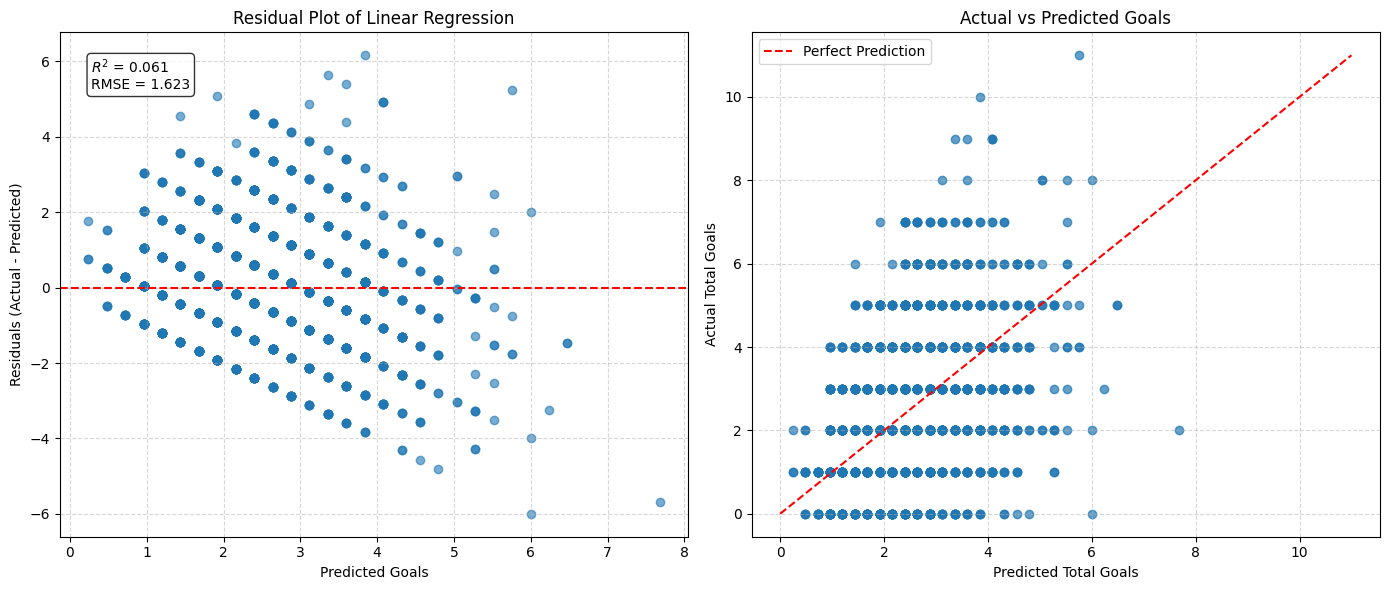

In [9]:
# Combined diagnostic plots: Residual Plot + Actual vs Predicted

residuals = scoredGoalDataTest - scoredGoalDataPred

plt.figure(figsize=(14,6))

# --------------------- 1) Residual Plot ---------------------
plt.subplot(1, 2, 1)
plt.scatter(scoredGoalDataPred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Goals")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot of Linear Regression")
plt.grid(True, linestyle="--", alpha=0.5)

# Annotate R² and RMSE
plt.text(
    0.05, 0.95,
    f"$R^2$ = {coffDetermination:.3f}\nRMSE = {rmse:.3f}",
    transform=plt.gca().transAxes,
    va="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
)

# --------------------- 2) Actual vs Predicted ---------------------
plt.subplot(1, 2, 2)
plt.scatter(scoredGoalDataPred, scoredGoalDataTest, alpha=0.7)
max_goal = max(scoredGoalDataTest.max(), scoredGoalDataPred.max())
plt.plot([0, max_goal], [0, max_goal], "r--", label="Perfect Prediction")

plt.xlabel("Predicted Total Goals")
plt.ylabel("Actual Total Goals")
plt.title("Actual vs Predicted Goals")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


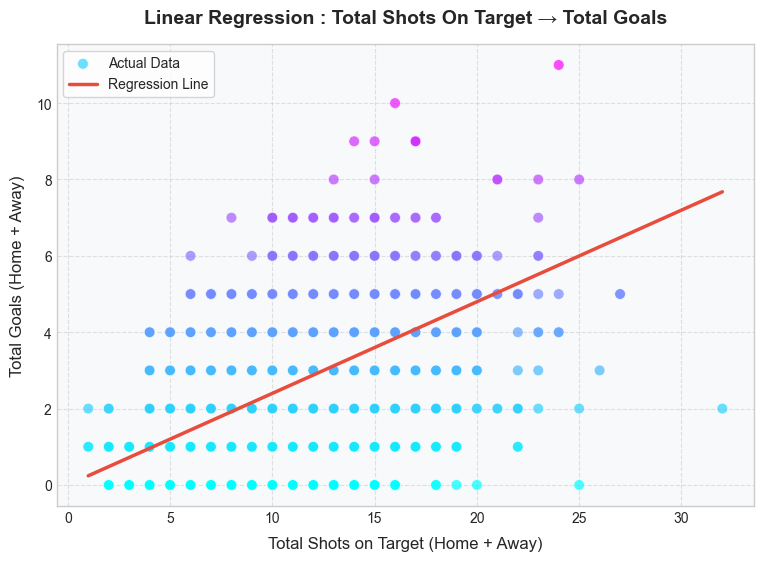

In [10]:
# figure size and style
plt.figure(figsize=(9,6))
plt.style.use("seaborn-v0_8-whitegrid")

# Scatter points with color gradient
plt.scatter(
    targetShotDataTest.flatten(),
    scoredGoalDataTest,
    c=scoredGoalDataTest,
    cmap="cool",        
    alpha=0.7,
    s=60,
    edgecolors="white",
    linewidth=0.6,
    label="Actual Data"
)

# Regression line (coral red)
xAxisline = np.linspace(targetShotDataTest.min(), targetShotDataTest.max(), 200).reshape(-1, 1)
yAxisline = lmfit.predict(xAxisline)  

plt.plot(
    xAxisline,
    yAxisline,
    color="#e74c3c",     
    linewidth=2.5,
    label="Regression Line"
)

# Update the Labels and title
plt.xlabel("Total Shots on Target (Home + Away)", fontsize=12, labelpad=8)
plt.ylabel("Total Goals (Home + Away)", fontsize=12, labelpad=8)
plt.title("Linear Regression : Total Shots On Target → Total Goals", fontsize=14, fontweight="bold", pad=15)

# Update the Grid and legend
plt.legend(facecolor="white", frameon=True, fontsize=10, loc="upper left")
plt.grid(True, linestyle="--", alpha=0.6)
plt.gca().set_facecolor("#f8f9fa")  

# Show the plot
plt.show()


/var/folders/gw/cz_jtl7d7qg71l2d1xr_3_480000gn/T/ipykernel_3436/2433390358.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  eplData.groupby("ShotsOnTarget_Range")["scoredGoal"]
/var/folders/gw/cz_jtl7d7qg71l2d1xr_3_480000gn/T/ipykernel_3436/2433390358.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


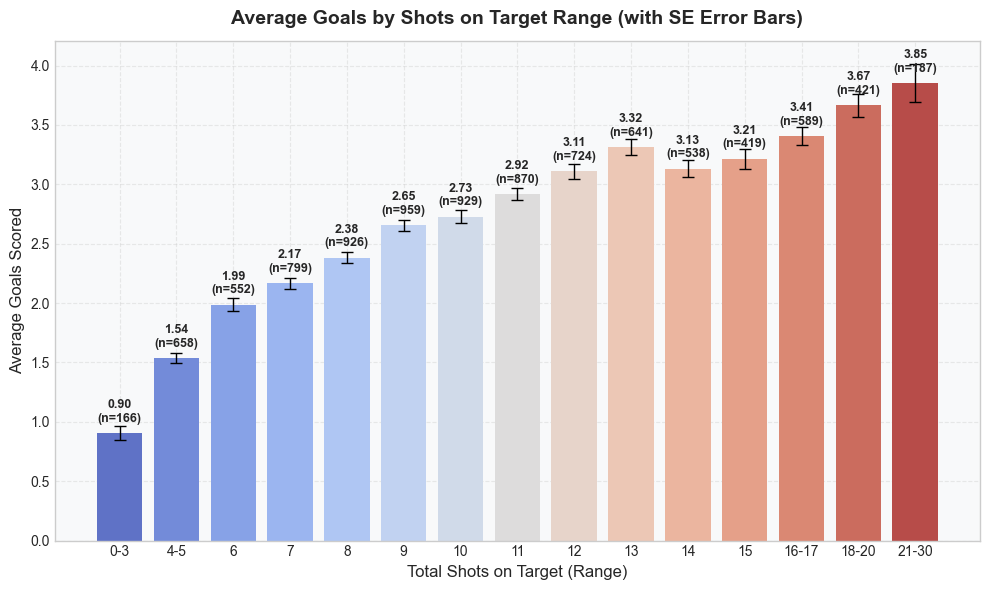

ShotsOnTarget_Range,AverageGoals,Matches,SD,SE,CI_lower,CI_upper
0-3,0.90,166,0.73,0.057,0.79,1.01
4-5,1.54,658,1.13,0.044,1.45,1.62
6,1.99,552,1.26,0.054,1.88,2.09
7,2.17,799,1.28,0.045,2.08,2.26
8,2.38,926,1.37,0.045,2.29,2.47
9,2.65,959,1.44,0.047,2.56,2.75
10,2.73,929,1.59,0.052,2.63,2.83
11,2.92,870,1.57,0.053,2.81,3.02
12,3.11,724,1.68,0.062,2.99,3.23
13,3.32,641,1.73,0.068,3.18,3.45


In [11]:
#  Average Goals Scored per Shots on Target Range 

# 1) Create bins for Total Shots on Target
eplData["ShotsOnTarget_Range"] = pd.cut(
    eplData["targetShot"], 
    bins=[0,3,5,6,7,8,9,10,11,12,13,14,15,17,20,30],
    labels=["0-3","4-5","6","7","8","9","10","11","12","13","14","15","16-17","18-20","21-30"]
)

# 2) Calculate average goals, count, SD, SE, CI
avg_stats = (
    eplData.groupby("ShotsOnTarget_Range")["scoredGoal"]
    .agg(["mean", "count", "std"])
    .reset_index()
    .rename(columns={"mean": "AverageGoals", "count": "Matches", "std": "SD"})
)

avg_stats["SE"] = avg_stats["SD"] / np.sqrt(avg_stats["Matches"])
avg_stats["CI_lower"] = avg_stats["AverageGoals"] - 1.96 * avg_stats["SE"]
avg_stats["CI_upper"] = avg_stats["AverageGoals"] + 1.96 * avg_stats["SE"]

# 3) Plot bar chart + SE error bars
plt.figure(figsize=(10,6))
plt.style.use("seaborn-v0_8-whitegrid")

ax = sns.barplot(
    x="ShotsOnTarget_Range",
    y="AverageGoals",
    data=avg_stats,
    palette="coolwarm"
)

# x positions for error bars (0,1,2,...)
x_pos = np.arange(len(avg_stats))

# Add SE error bars manually
ax.errorbar(
    x=x_pos,
    y=avg_stats["AverageGoals"],
    yerr=avg_stats["SE"],
    fmt="none",
    ecolor="black",
    elinewidth=1,
    capsize=4,
    capthick=1
)

# default ticks with our category labels
ax.set_xticks(x_pos)
ax.set_xticklabels(avg_stats["ShotsOnTarget_Range"])

# Add values on top of bars
for idx, row in avg_stats.iterrows():
    ax.text(
        idx,
        row["AverageGoals"] + 0.07,
        f"{row['AverageGoals']:.2f}\n(n={row['Matches']})",
        ha="center", va="bottom", fontsize=9, fontweight="bold"
    )

# Labels and title
plt.title("Average Goals by Shots on Target Range (with SE Error Bars)", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Total Shots on Target (Range)", fontsize=12)
plt.ylabel("Average Goals Scored", fontsize=12)

plt.grid(True, linestyle="--", alpha=0.4)
plt.gca().set_facecolor("#f8f9fa")
plt.tight_layout()
plt.show()

# 4) Summary table display
display(
    avg_stats.style
        .set_caption("Average Goals, SD, SE, and 95% CI by Shots on Target Range")
        .hide(axis="index")
        .format({
            "AverageGoals": "{:.2f}",
            "SD": "{:.2f}",
            "SE": "{:.3f}",
            "CI_lower": "{:.2f}",
            "CI_upper": "{:.2f}"
        })
)

##### This regression is trying to predict how many goals are likely to be scored in a match based on how many shots on target occur.

##### ---------------------------------------------------------------------------------
#####  Interpretation:
#####  - The linear model explains about X% of the variance in total goals (R^2 ≈ ...)
#####  - On average, each additional shot on target is associated with about coef goals.
#####  - However, residuals show large variability, especially at higher shot counts,
#####    indicating that shots on target alone are not sufficient to reliably predict goals.
#####  - This justifies the later use of Poisson regression and multi-feature ML models.
##### ---------------------------------------------------------------------------------


### Reference 
#### Was taken from Predicting Football Match Outcomes With Machine Learning Approaches by Bing Shen Choi, Lee Kien Foo, Sook-Ling Chua from Multimedia University - MMU Cyberjaya, Malaysia. This paper shows how football performance indicators such as shots on target, possession, and passes can be used with regression and machine learning models to predict match outcomes and goal counts

## 5. Poisson Regression
### Independent variable: targetShot  
### Dependent variable: scoredGoal  
### It estimates the probability of different goal counts occurring based on predictors like **shots on target**, **fouls**, or other match statistics.  This model is ideal when the outcome variable (goals) is discrete and non-negative, making it more suitable than linear regression for predicting football goal counts.

In [12]:
# Poisson Regression Models (with and without intercept)
# Using statsmodels to fit Poisson regression models
# I will fit two models: one without an intercept and one with an intercept.
# Import statsmodels.api as sm already done at the top

# (A) NO intercept
poisNoConst = sm.GLM(scoredGoalDataTrain, targetShotDataTrain, family=sm.families.Poisson()).fit()
# Summary of the model
print("=== Poisson (NO intercept) ===")
print(poisNoConst.summary())
print("=== Poisson (NO intercept) AIC ===", poisNoConst.aic)
print("=== Poisson (NO intercept) BIC ===",poisNoConst.bic)

# (B) WITH intercept
targetShotDataTrainConst = sm.add_constant(targetShotDataTrain, has_constant="add")
targetShotDataTestConst  = sm.add_constant(targetShotDataTest,  has_constant="add")
poisWithConst = sm.GLM(scoredGoalDataTrain, targetShotDataTrainConst, family=sm.families.Poisson()).fit()
# Summary of the model
print("\n=== Poisson (WITH intercept) ===")
print(poisWithConst.summary())
print("\n=== Poisson (WITH intercept) ===", poisWithConst.aic)
print("\n=== Poisson (WITH intercept) ===", poisWithConst.bic)

=== Poisson (NO intercept) ===
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                 7504
Model:                            GLM   Df Residuals:                     7503
Model Family:                 Poisson   Df Model:                            0
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -14023.
Date:                Mon, 05 Oct 2026   Deviance:                       8261.2
Time:                        14:14:55   Pearson chi2:                 7.97e+03
No. Iterations:                     5   Pseudo R-squ. (CS):            0.03993
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0822

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/genmod/generalized_linear_model.py:1923: FutureWarning: The bic value is computed using the deviance formula. After 0.13 this will change to the log-likelihood based formula. This change has no impact on the relative rank of models compared using BIC. You can directly access the log-likelihood version using the `bic_llf` attribute. You can suppress this message by calling statsmodels.genmod.generalized_linear_model.SET_USE_BIC_LLF with True to get the LLF-based version now or False to retainthe deviance version.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/genmod/generalized_linear_model.py:1923: FutureWarning: The bic value is computed using the deviance formula. After 0.13 this will change to the log-likelihood based formula. This change has no impact on the relative rank of models compared using BIC. You can directly access the l

### 5.2 Predict and evaluate the model

### Predict on TEST set

In [13]:
# Predict on TEST set
predNoConst  = poisNoConst.predict(targetShotDataTest)
predWithConst = poisWithConst.predict(targetShotDataTestConst)

# For quick inspection (rounded counts)
predNoConst_r  = np.round(predNoConst)
predWithConst_r = np.round(predWithConst)

# % of matches where rounded prediction equals actual
acc_no = (np.round(predNoConst) == scoredGoalDataTest).mean()
acc_wi = (np.round(predWithConst) == scoredGoalDataTest).mean()
print("Exact goal match rate (No Const):", acc_no)
print("Exact goal match rate (With Const):", acc_wi)

# Print the values for reference
print("Predictions (No Const):", predNoConst)
print("Predictions (With Const):", predWithConst)

# Dispersion calculation
print("Deviance / df_resid (no const):", poisNoConst.deviance / poisNoConst.df_resid)
print("Deviance / df_resid (with const):", poisWithConst.deviance / poisWithConst.df_resid)

# Values close to 1 → Poisson assumption OK
# Values much larger than 1 → overdispersion 

Exact goal match rate (No Const): 0.26332622601279315
Exact goal match rate (With Const): 0.2547974413646055
Predictions (No Const): [2.4708848  3.16223461 5.17937396 ... 5.17937396 2.2758238  4.04702305]
Predictions (With Const): [2.70819452 3.12479104 4.16009486 ... 4.16009486 2.58205891 3.60547183]
Deviance / df_resid (no const): 1.1010564434721684
Deviance / df_resid (with const): 1.0243793824031164


In [14]:

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# Compile metrics into a DataFrame for comparison
metrics_eplData = pd.DataFrame({
    "Model": ["Poisson (No Intercept)", "Poisson (With Intercept)"],
    "MAE": [
        mean_absolute_error(scoredGoalDataTest, predNoConst),
        mean_absolute_error(scoredGoalDataTest, predWithConst)
    ],
    "RMSE": [
        rmse(scoredGoalDataTest, predNoConst),
        rmse(scoredGoalDataTest, predWithConst)
    ],
    # Train-fit metrics from statsmodels (useful for model selection)
    "Train AIC": [poisNoConst.aic, poisWithConst.aic],
    "Train BIC": [poisNoConst.bic, poisWithConst.bic],
    "Train Deviance": [poisNoConst.deviance, poisWithConst.deviance],
    "Train Log-Likelihood": [poisNoConst.llf, poisWithConst.llf]
})

# Display comparison table
print("\n=== Poisson Models — Comparison (Test Metrics + Train Fit Stats) ===")
display(
    metrics_eplData.style
        .hide(axis="index")
        .format({"MAE":"{:.3f}","RMSE":"{:.3f}","Train AIC":"{:.1f}", "Train BIC":"{:.1f}","Train Deviance":"{:.1f}","Train Log-Likelihood":"{:.1f}"})
        .set_caption("⚽ Poisson Regression — With vs Without Intercept")
)


=== Poisson Models — Comparison (Test Metrics + Train Fit Stats) ===


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/genmod/generalized_linear_model.py:1923: FutureWarning: The bic value is computed using the deviance formula. After 0.13 this will change to the log-likelihood based formula. This change has no impact on the relative rank of models compared using BIC. You can directly access the log-likelihood version using the `bic_llf` attribute. You can suppress this message by calling statsmodels.genmod.generalized_linear_model.SET_USE_BIC_LLF with True to get the LLF-based version now or False to retainthe deviance version.
  warnings.warn(


Model,MAE,RMSE,Train AIC,Train BIC,Train Deviance,Train Log-Likelihood
Poisson (No Intercept),1.291,1.671,28047.5,-58689.5,8261.2,-14022.8
Poisson (With Intercept),1.243,1.575,27473.2,-59256.9,7684.9,-13734.6


### Simple comparison table of first 100 predictions

In [15]:
compare_rows = min(100, len(scoredGoalDataTest))
# Simple comparison table of first 100 predictions
sample_cmp = pd.DataFrame({
    "TotalShotsOnTarget": targetShotDataTest.flatten()[:compare_rows],
    "Actual Goals": scoredGoalDataTest[:compare_rows],
    "Prediction With No Const": predNoConst[:compare_rows],
    "Prediction With Const": predWithConst[:compare_rows],
})

# Round numeric columns to whole numbers
for col in ["TotalShotsOnTarget", "Actual Goals", "Prediction With No Const", "Prediction With Const"]:
    sample_cmp[col] = pd.to_numeric(sample_cmp[col], errors="coerce").round(0)

# Display the sample comparison table with formatting
display(
    sample_cmp.style
        .hide(axis="index")
        .format({
            "TotalShotsOnTarget": "{:.0f}",
            "Actual Goals": "{:.0f}",
            "Prediction With No Const": "{:.0f}",
            "Prediction With Const": "{:.0f}"
        })
        .set_table_styles([
            {"selector": "tbody", "props": [("display", "block"), ("max-height", "380px"), ("overflow-y", "scroll")]},
            {"selector": "thead, tbody tr", "props": [("display", "table"), ("width", "100%"), ("table-layout", "fixed")]}
        ])
)

# The comparison table shows the first 100 predictions from both Poisson regression models against the actual goals scored.


TotalShotsOnTarget,Actual Goals,Prediction With No Const,Prediction With Const
11,2,2,3
14,3,3,3
20,4,5,4
8,2,2,2
9,0,2,2
7,1,2,2
13,6,3,3
9,1,2,2
8,4,2,2
11,4,2,3


### 5.3 Visualize the Regression Plot

/var/folders/gw/cz_jtl7d7qg71l2d1xr_3_480000gn/T/ipykernel_3436/2609870054.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rangeCounts = visualDisplay.groupby("ShotRange").size().reset_index(name="MatchCount")
/var/folders/gw/cz_jtl7d7qg71l2d1xr_3_480000gn/T/ipykernel_3436/2609870054.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avgByBin = visualDisplay.groupby("ShotRange")[["Actual Goals","Predict with No Const","Predict with Const"]].mean().reset_index()
/var/folders/gw/cz_jtl7d7qg71l2d1xr_3_480000gn/T/ipykernel_3436/2609870054.py:50: UserWarning: set_ticklabels() should only be used with a fixe

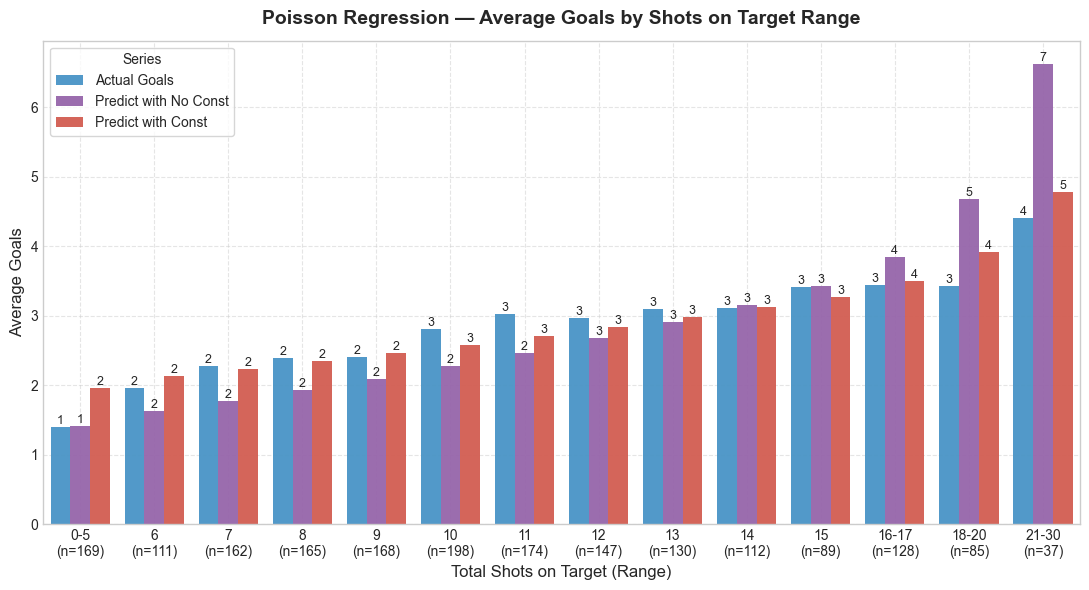

In [16]:
# Visualization: Average Goals by Shots on Target Range (Actual vs Poisson Predictions)
visualDisplay = pd.DataFrame({
    "TotalShotsOnTarget": targetShotDataTest.flatten(),
    "Actual Goals": scoredGoalDataTest,
    "Predict with No Const": predNoConst,
    "Predict with Const": predWithConst
})

# Create a bin for Shots on Target
visualDisplay["ShotRange"] = pd.cut(
    visualDisplay["TotalShotsOnTarget"],
    bins=[0,5,6,7,8,9,10,11,12,13,14,15,17,20,30],
    labels=["0-5","6","7","8","9","10","11","12","13","14","15","16-17","18-20","21-30"]
)

# Counts per bin
rangeCounts = visualDisplay.groupby("ShotRange").size().reset_index(name="MatchCount")

# Create mean goals per bin (actual + both models)
avgByBin = visualDisplay.groupby("ShotRange")[["Actual Goals","Predict with No Const","Predict with Const"]].mean().reset_index()
avgByBin = avgByBin.merge(rangeCounts, on="ShotRange", how="left")

# Melt for grouped plot
avgMelt = avgByBin.melt(
    id_vars=["ShotRange","MatchCount"],
    value_vars=["Actual Goals","Predict with No Const","Predict with Const"],
    var_name="Type",
    value_name="AverageGoals"
)

plt.figure(figsize=(11,6))
plt.style.use("seaborn-v0_8-whitegrid")

# Grouped bar plot
ax = sns.barplot(
    x="ShotRange",
    y="AverageGoals",
    hue="Type",
    data=avgMelt,
    palette={
        "Actual Goals": "#3498db",
        "Predict with No Const": "#9b59b6",
        "Predict with Const": "#e74c3c"
    },
    alpha=0.95
)

# Update X tick labels with counts
updatedTickLabels = [f"{sr}\n(n={cnt})" for sr, cnt in zip(avgByBin["ShotRange"], avgByBin["MatchCount"])]
ax.set_xticklabels(updatedTickLabels)

# Update Labels and title
plt.title("Poisson Regression — Average Goals by Shots on Target Range", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Total Shots on Target (Range)", fontsize=12)
plt.ylabel("Average Goals", fontsize=12)
plt.legend(title="Series", frameon=True, facecolor="white", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)

# Add value labels on bars
for container in ax.containers:
    plt.bar_label(container, fmt="%.0f", label_type="edge", fontsize=9)

# Show the plot
plt.tight_layout()
plt.show()

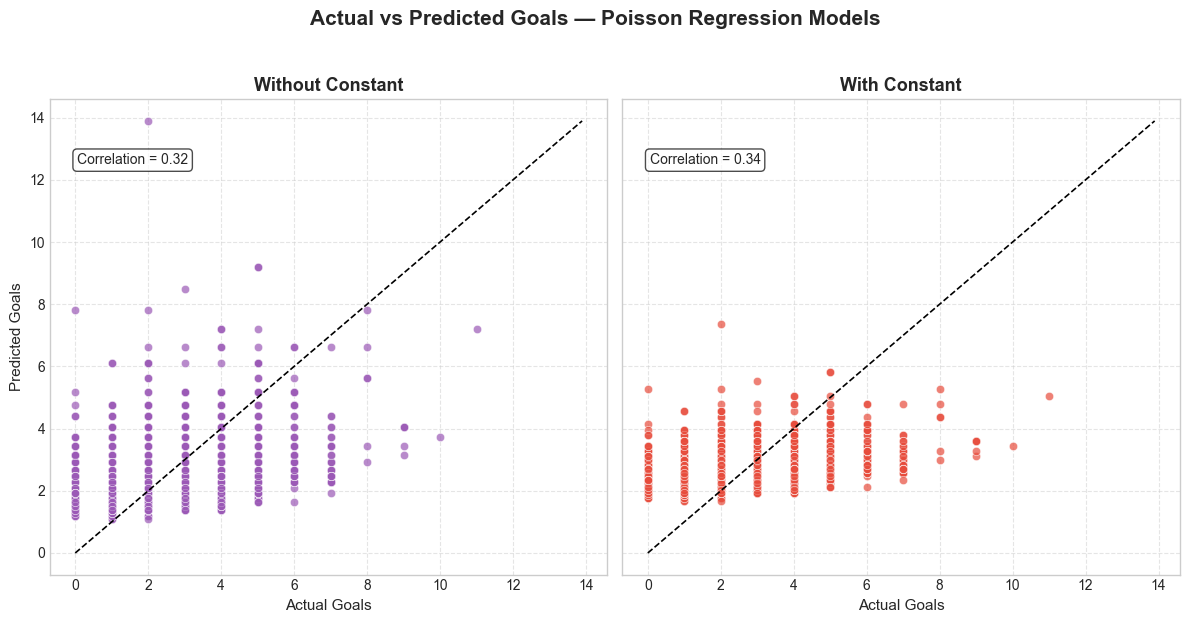

In [17]:
# Scatter Plots: Actual vs Predicted Goals (Side-by-Side Comparison)
plt.style.use("seaborn-v0_8-whitegrid")

# Create a 1x2 subplot
fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)

# Common max for scaling
max_val = max(
    visualDisplay["Actual Goals"].max(),
    visualDisplay["Predict with No Const"].max(),
    visualDisplay["Predict with Const"].max()
)

# Plot 1: Without Constant
sns.scatterplot(
    ax=axes[0],
    x=visualDisplay["Actual Goals"],
    y=visualDisplay["Predict with No Const"],
    color="#9b59b6",
    alpha=0.7
)
axes[0].plot([0, max_val], [0, max_val], "k--", lw=1.2)
axes[0].set_title("Without Constant", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Actual Goals", fontsize=11)
axes[0].set_ylabel("Predicted Goals", fontsize=11)
axes[0].grid(True, linestyle="--", alpha=0.5)
corr_no_const = visualDisplay["Actual Goals"].corr(visualDisplay["Predict with No Const"])
axes[0].text(0.05, max_val*0.9,
             f"Correlation = {corr_no_const:.2f}",
             fontsize=10, bbox=dict(facecolor="white", alpha=0.7, boxstyle="round,pad=0.3"))

# Plot 2: With Constant
sns.scatterplot(
    ax=axes[1],
    x=visualDisplay["Actual Goals"],
    y=visualDisplay["Predict with Const"],
    color="#e74c3c",
    alpha=0.7
)
axes[1].plot([0, max_val], [0, max_val], "k--", lw=1.2)
axes[1].set_title("With Constant", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Actual Goals", fontsize=11)
axes[1].set_ylabel("")
axes[1].grid(True, linestyle="--", alpha=0.5)
corr_const = visualDisplay["Actual Goals"].corr(visualDisplay["Predict with Const"])
axes[1].text(0.05, max_val*0.9,
             f"Correlation = {corr_const:.2f}",
             fontsize=10, bbox=dict(facecolor="white", alpha=0.7, boxstyle="round,pad=0.3"))

# Layout Adjustments
fig.suptitle("Actual vs Predicted Goals — Poisson Regression Models", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


##### Simple residual / Goodness-of-fit plot

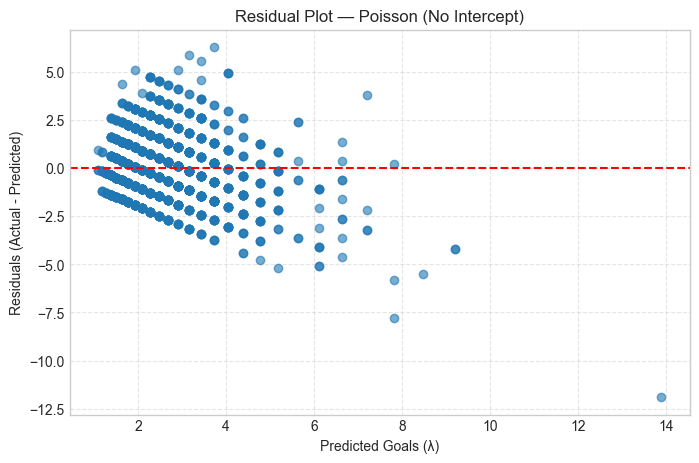

In [18]:
resid_no = scoredGoalDataTest - predNoConst   

plt.figure(figsize=(8,5))
plt.scatter(predNoConst, resid_no, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Goals (λ)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot — Poisson (No Intercept)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


### 5.4 Visualize the Regression table

In [19]:
# Build a tidy summary from avg_by_bin created earlier (keep your original column names)
regressionTable = avgByBin[["ShotRange", "MatchCount", "Actual Goals", "Predict with No Const", "Predict with Const"]].copy()
regressionTable.columns = [
    "Shot Range",
    "Number of Matches",
    "Avg Actual Goals",
    "Avg Pred (No Intercept)",
    "Avg Pred (With Intercept)"
]

# Round numeric columns
for col in ["Avg Actual Goals", "Avg Pred (No Intercept)", "Avg Pred (With Intercept)"]:
    regressionTable[col] = pd.to_numeric(regressionTable[col], errors="coerce").round(2)

# Compute accuracy safely (avoid divide-by-zero for ranges with 0 actual goals)
actual = regressionTable["Avg Actual Goals"].astype(float)
pred_no = regressionTable["Avg Pred (No Intercept)"].astype(float)
pred_wi = regressionTable["Avg Pred (With Intercept)"].astype(float)

# Calculate accuracy percentages
regressionTable["Accuracy (No Intercept) %"] = np.where(
    actual > 0,
    100 - (np.abs(pred_no - actual) / actual) * 100,
    np.nan  
).round(2)

regressionTable["Accuracy (With Intercept) %"] = np.where(
    actual > 0,
    100 - (np.abs(pred_wi - actual) / actual) * 100,
    np.nan  
).round(2)

# Keep NaNs as NaN so we can show a dash instead of 0
numeric_cols = regressionTable.select_dtypes(include=["number"]).columns
regressionTable[numeric_cols] = regressionTable[numeric_cols].replace([np.inf, -np.inf], np.nan)

# Define formatters for better display
formatters = {
    "Number of Matches": "{:,}",                     
    "Avg Actual Goals": "{:.0f}",                    
    "Avg Pred (No Intercept)": "{:.0f}",
    "Avg Pred (With Intercept)": "{:.0f}",
    "Accuracy (No Intercept) %": lambda x: "" if pd.isna(x) else f"{x:.0f}%",
    "Accuracy (With Intercept) %": lambda x: "" if pd.isna(x) else f"{x:.0f}%"
}

# Display the regression summary table with formatting
display(
    regressionTable.style
        .set_caption("⚽ Poisson Regression — Average Goals & Accuracy by SOT Range (Actual vs No/With Intercept)")
        .set_table_styles([
            {"selector": "caption", "props": [("font-size", "14px"), ("font-weight", "bold"), ("text-align", "center")]},
            {"selector": "th", "props": [("background-color", "#700000"), ("color", "white"), ("font-weight", "bold")]}
        ])
        .hide(axis="index")
        .format(formatters, na_rep="—")  
)


Shot Range,Number of Matches,Avg Actual Goals,Avg Pred (No Intercept),Avg Pred (With Intercept),Accuracy (No Intercept) %,Accuracy (With Intercept) %
0-5,169,1,1,2,99%,60%
6,111,2,2,2,84%,91%
7,162,2,2,2,78%,98%
8,165,2,2,2,81%,98%
9,168,2,2,2,88%,98%
10,198,3,2,3,81%,91%
11,174,3,2,3,82%,90%
12,147,3,3,3,90%,96%
13,130,3,3,3,94%,96%
14,112,3,3,3,99%,100%


##### -----------------------------------------------------------
##### Interpretation:
##### - Poisson models provide expected goal counts conditional
#####   on total shots on target.
##### - Comparing AIC/BIC and MAE/RMSE shows that [with/without]
#####   intercept performs slightly better.
##### - However, deviance/df_resid >> 1 indicates overdispersion,
#####   so the standard Poisson assumption Var(Y)=E(Y) is violated.
#####   This motivates more flexible count models (e.g. Negative
#####   Binomial) or richer feature sets in subsequent sections.
##### -----------------------------------------------------------


#### Random Forest Regressor
##### This code trains two Random Forest models — one using all match features and another using only shots on target — to predict home and away goals. It then evaluates their accuracy, calculates per-match prediction errors, and exports a clean CSV containing actual goals, predicted goals, and accuracy percentages for every Premier League match.

In [20]:
# Data Preprocessing for Advanced Models
# Ensure required columns are present
required_cols = [
    "Season","MatchDate","HomeTeam","AwayTeam",
    "FullTimeHomeGoals","FullTimeAwayGoals",
    "HomeShotsOnTarget","AwayShotsOnTarget"
]
# Check for missing required columns
missing = [c for c in required_cols if c not in eplData.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# Convert MatchDate to datetime and drop rows with missing critical data
eplData["MatchDate"] = pd.to_datetime(eplData["MatchDate"], errors="coerce")
eplData = eplData.dropna(subset=["MatchDate","FullTimeHomeGoals","FullTimeAwayGoals",
                       "HomeShotsOnTarget","AwayShotsOnTarget"]).copy()
# Extract date features
eplData["MatchYear"]  = eplData["MatchDate"].dt.year
eplData["MatchMonth"] = eplData["MatchDate"].dt.month
eplData["MatchDay"]   = eplData["MatchDate"].dt.day
eplData["MatchDoW"]   = eplData["MatchDate"].dt.dayofweek
# Define target variables
y = eplData[["FullTimeHomeGoals","FullTimeAwayGoals"]].astype(float)


##### Define features 

In [21]:
categorical_cols = ["Season","HomeTeam","AwayTeam"]
# Define numeric columns
numeric_candidates = [
    "MatchYear","MatchMonth","MatchDay","MatchDoW",
    "HomeShots","AwayShots",
    "HomeShotsOnTarget","AwayShotsOnTarget",
    "HomeCorners","AwayCorners",
    "HomeFouls","AwayFouls",
    "HomeYellowCards","AwayYellowCards",
    "HomeRedCards","AwayRedCards"
]
# Filter numeric columns to those present in the DataFrame
numeric_cols_full = [c for c in numeric_candidates if c in eplData.columns]

# Initialise new history columns
history_cols = [
    "Home_AvgGoalsFor_Last5","Home_AvgGoalsAgainst_Last5",
    "Home_AvgSOT_Last5","Home_AvgPoints_Last5",
    "Away_AvgGoalsFor_Last5","Away_AvgGoalsAgainst_Last5",
    "Away_AvgSOT_Last5","Away_AvgPoints_Last5"
]

for col in history_cols:
    eplData[col] = np.nan

teams = sorted(set(eplData["HomeTeam"]).union(set(eplData["AwayTeam"])))
window_n = 5  # last 5 matches

for team in teams:
    mask = (eplData["HomeTeam"] == team) | (eplData["AwayTeam"] == team)
    team_matches = eplData.loc[mask].sort_values("MatchDate").copy()

    # Goals for/against, shots on target, and points from the team's perspective
    goals_for = np.where(team_matches["HomeTeam"] == team,
                         team_matches["FullTimeHomeGoals"],
                         team_matches["FullTimeAwayGoals"])
    goals_against = np.where(team_matches["HomeTeam"] == team,
                             team_matches["FullTimeAwayGoals"],
                             team_matches["FullTimeHomeGoals"])
    sot_for = np.where(team_matches["HomeTeam"] == team,
                       team_matches["HomeShotsOnTarget"],
                       team_matches["AwayShotsOnTarget"])

    # Points: 3 for win, 1 for draw, 0 for loss
    points = np.where(goals_for > goals_against, 3,
              np.where(goals_for == goals_against, 1, 0))

    # Rolling averages based only on PREVIOUS matches (shift before rolling)
    gf_roll  = pd.Series(goals_for).shift().rolling(window_n).mean()
    ga_roll  = pd.Series(goals_against).shift().rolling(window_n).mean()
    sot_roll = pd.Series(sot_for).shift().rolling(window_n).mean()
    pts_roll = pd.Series(points).shift().rolling(window_n).mean()

    # Assign back to eplData (separate home/away columns)
    for idx, gf, ga, sot, pts in zip(team_matches.index,
                                     gf_roll, ga_roll, sot_roll, pts_roll):
        if eplData.at[idx, "HomeTeam"] == team:
            eplData.at[idx, "Home_AvgGoalsFor_Last5"]      = gf
            eplData.at[idx, "Home_AvgGoalsAgainst_Last5"]  = ga
            eplData.at[idx, "Home_AvgSOT_Last5"]           = sot
            eplData.at[idx, "Home_AvgPoints_Last5"]        = pts
        else:
            eplData.at[idx, "Away_AvgGoalsFor_Last5"]      = gf
            eplData.at[idx, "Away_AvgGoalsAgainst_Last5"]  = ga
            eplData.at[idx, "Away_AvgSOT_Last5"]           = sot
            eplData.at[idx, "Away_AvgPoints_Last5"]        = pts

# History-only feature list
history_feature_cols = [
    "Home_AvgGoalsFor_Last5","Home_AvgGoalsAgainst_Last5",
    "Home_AvgSOT_Last5","Home_AvgPoints_Last5",
    "Away_AvgGoalsFor_Last5","Away_AvgGoalsAgainst_Last5",
    "Away_AvgSOT_Last5","Away_AvgPoints_Last5"
]

X_history = eplData[history_feature_cols].copy()


# Define feature sets
X_full = eplData[categorical_cols + numeric_cols_full].copy()
X_sot  = eplData[["HomeShotsOnTarget","AwayShotsOnTarget"]].copy()

#  No-SOT feature set (all numeric EXCEPT SOT)
numeric_cols_no_sot = [c for c in numeric_cols_full
                       if c not in ["HomeShotsOnTarget","AwayShotsOnTarget"]]

X_no_sot = eplData[categorical_cols + numeric_cols_no_sot].copy()


# display first few rows of feature sets
print("Full Feature Set:")
display(X_full.head())
print("\nShots on Target Feature Set:")
display(X_sot.head())
# No-Shots on Target Feature Set:
display(X_no_sot.head())
print("\nHistory-Only Feature Set:")
display(X_history.head())
print("\nTarget Variables:")
display(y.head())

Full Feature Set:


,Season,HomeTeam,AwayTeam,MatchYear,MatchMonth,MatchDay,MatchDoW,HomeShots,AwayShots,HomeShotsOnTarget,AwayShotsOnTarget,HomeCorners,AwayCorners,HomeFouls,AwayFouls,HomeYellowCards,AwayYellowCards,HomeRedCards,AwayRedCards
0,2000/01,Charlton,Man City,2000,8,19,5,17,8,14,4,6,6,13,12,1,2,0,0
1,2000/01,Chelsea,West Ham,2000,8,19,5,17,12,10,5,7,7,19,14,1,2,0,0
2,2000/01,Coventry,Middlesbrough,2000,8,19,5,6,16,3,9,8,4,15,21,5,3,1,0
3,2000/01,Derby,Southampton,2000,8,19,5,6,13,4,6,5,8,11,13,1,1,0,0
4,2000/01,Leeds,Everton,2000,8,19,5,17,12,8,6,6,4,21,20,1,3,0,0



Shots on Target Feature Set:


,HomeShotsOnTarget,AwayShotsOnTarget
0,14,4
1,10,5
2,3,9
3,4,6
4,8,6


,Season,HomeTeam,AwayTeam,MatchYear,MatchMonth,MatchDay,MatchDoW,HomeShots,AwayShots,HomeCorners,AwayCorners,HomeFouls,AwayFouls,HomeYellowCards,AwayYellowCards,HomeRedCards,AwayRedCards
0,2000/01,Charlton,Man City,2000,8,19,5,17,8,6,6,13,12,1,2,0,0
1,2000/01,Chelsea,West Ham,2000,8,19,5,17,12,7,7,19,14,1,2,0,0
2,2000/01,Coventry,Middlesbrough,2000,8,19,5,6,16,8,4,15,21,5,3,1,0
3,2000/01,Derby,Southampton,2000,8,19,5,6,13,5,8,11,13,1,1,0,0
4,2000/01,Leeds,Everton,2000,8,19,5,17,12,6,4,21,20,1,3,0,0



History-Only Feature Set:


,Home_AvgGoalsFor_Last5,Home_AvgGoalsAgainst_Last5,Home_AvgSOT_Last5,Home_AvgPoints_Last5,Away_AvgGoalsFor_Last5,Away_AvgGoalsAgainst_Last5,Away_AvgSOT_Last5,Away_AvgPoints_Last5
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Target Variables:


,FullTimeHomeGoals,FullTimeAwayGoals
0,4.0,0.0
1,4.0,2.0
2,1.0,3.0
3,2.0,2.0
4,2.0,0.0


#### Preprocessing

In [22]:
# Preprocessing pipelines
ohe_kwargs = {"handle_unknown": "ignore"}
if "sparse_output" in inspect.signature(OneHotEncoder).parameters:
    ohe_kwargs["sparse_output"] = False
else:
    ohe_kwargs["sparse"] = False
# Preprocessing for full feature set
preprocess_full = ColumnTransformer([
    ("cat", OneHotEncoder(**ohe_kwargs), categorical_cols),
    ("num", SimpleImputer(strategy="median"), numeric_cols_full),
])
# SOT-only preprocessor
preprocess_sot = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), ["HomeShotsOnTarget","AwayShotsOnTarget"]),
])
# No-SOT preprocessor
preprocess_no_sot = ColumnTransformer([
    ("cat", OneHotEncoder(**ohe_kwargs), categorical_cols),
    ("num", SimpleImputer(strategy="median"), numeric_cols_no_sot),
])
# History-only preprocessor (all numeric rolling features)
preprocess_history = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), history_feature_cols),
])



In [23]:
# Random Forest Regressor for full feature set and Shots on Target
rf_full = RandomForestRegressor(n_estimators=400, random_state=42, n_jobs=-1)
rf_sot  = RandomForestRegressor(n_estimators=400, random_state=42, n_jobs=-1)
rf_no_sot = RandomForestRegressor(n_estimators=400, random_state=42, n_jobs=-1)
rf_hist   = RandomForestRegressor(n_estimators=400, random_state=42, n_jobs=-1)

# Build complete pipelines
model_full = Pipeline([("prep", preprocess_full), ("rf", rf_full)])
model_sot  = Pipeline([("prep", preprocess_sot),  ("rf", rf_sot)])
model_no_sot = Pipeline([("prep", preprocess_no_sot), ("rf", rf_no_sot)])
model_history = Pipeline([("prep", preprocess_history), ("rf", rf_hist)])


#### Train/Test Split

In [24]:
# Train-test split
SOT_train, SOT_test, goal_train, goal_test = train_test_split(X_full, y, test_size=0.2, random_state=42)
Xs_train = X_sot.loc[SOT_train.index]
Xs_test  = X_sot.loc[SOT_test.index]
Xnosot_train = X_no_sot.loc[SOT_train.index]
Xnosot_test  = X_no_sot.loc[SOT_test.index]
Xhist_train  = X_history.loc[SOT_train.index]
Xhist_test   = X_history.loc[SOT_test.index]

# Fit models
model_full.fit(SOT_train, goal_train)
model_sot.fit(Xs_train, goal_train)
model_no_sot.fit(Xnosot_train, goal_train)
model_history.fit(Xhist_train, goal_train)


,steps,"[('prep', ...), ('rf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


#### Prediction for ALL matches

In [25]:
# Predictions on entire dataset
predAllFull = model_full.predict(X_full)
predAllSot  = model_sot.predict(X_sot)
predAllNoSot  = model_no_sot.predict(X_no_sot)
predAllHist   = model_history.predict(X_history)

# Add predictions to eplDataExport DataFrame
eplDataExport = eplData.copy()
eplDataExport["Pred_HomeGoals_Full"] = np.round(predAllFull[:,0]).astype(int)
eplDataExport["Pred_AwayGoals_Full"] = np.round(predAllFull[:,1]).astype(int)
eplDataExport["Pred_HomeGoals_SOT"]  = np.round(predAllSot[:,0]).astype(int)
eplDataExport["Pred_AwayGoals_SOT"]  = np.round(predAllSot[:,1]).astype(int)
eplDataExport["Pred_HomeGoals_NoSOT"]  = np.round(predAllNoSot[:,0]).astype(int)
eplDataExport["Pred_AwayGoals_NoSOT"]  = np.round(predAllNoSot[:,1]).astype(int)
eplDataExport["Pred_HomeGoals_History"] = np.round(predAllHist[:,0]).astype(int)
eplDataExport["Pred_AwayGoals_History"] = np.round(predAllHist[:,1]).astype(int)


print("Feature sets prepared and models initialized.")

# Display a preview of predictions from different models
preview = pd.DataFrame({
    "Pred_HomeGoals_Full":     eplDataExport["Pred_HomeGoals_Full"].head(5),
    "Pred_HomeGoals_SOT":      eplDataExport["Pred_HomeGoals_SOT"].head(5),
    "Pred_HomeGoals_NoSOT":    eplDataExport["Pred_HomeGoals_NoSOT"].head(5),
    "Pred_HomeGoals_History":  eplDataExport["Pred_HomeGoals_History"].head(5),
    "Pred_AwayGoals_Full":     eplDataExport["Pred_AwayGoals_Full"].head(5),
    "Pred_AwayGoals_SOT":      eplDataExport["Pred_AwayGoals_SOT"].head(5),
    "Pred_AwayGoals_NoSOT":    eplDataExport["Pred_AwayGoals_NoSOT"].head(5),
    "Pred_AwayGoals_History":  eplDataExport["Pred_AwayGoals_History"].head(5),
})
print(preview)


Feature sets prepared and models initialized.
   Pred_HomeGoals_Full  Pred_HomeGoals_SOT  Pred_HomeGoals_NoSOT  \
0                    3                   3                     2   
1                    3                   2                     3   
2                    1                   1                     1   
3                    1                   1                     1   
4                    2                   2                     2   

   Pred_HomeGoals_History  Pred_AwayGoals_Full  Pred_AwayGoals_SOT  \
0                       2                    1                   1   
1                       2                    2                   1   
2                       2                    3                   3   
3                       2                    1                   1   
4                       2                    0                   1   

   Pred_AwayGoals_NoSOT  Pred_AwayGoals_History  
0                     1                       1  
1                     2 

#### Accuracy (% within 1 plus goal)

In [26]:
def fuzzy_accuracy(true, pred):
    diff = np.abs(true - pred)
    return np.where(diff == 0, 100,
           np.where(diff == 1, 50, 0))

# Full model
eplDataExport["AccPct_Home_Full( in %)"] = fuzzy_accuracy(
    eplDataExport["FullTimeHomeGoals"],
    eplDataExport["Pred_HomeGoals_Full"]
)
eplDataExport["AccPct_Away_Full( in %)"] = fuzzy_accuracy(
    eplDataExport["FullTimeAwayGoals"],
    eplDataExport["Pred_AwayGoals_Full"]
)

# SOT-only model
eplDataExport["AccPct_Home_SOT ( in %)"] = fuzzy_accuracy(
    eplDataExport["FullTimeHomeGoals"],
    eplDataExport["Pred_HomeGoals_SOT"]
)
eplDataExport["AccPct_Away_SOT( in %)"] = fuzzy_accuracy(
    eplDataExport["FullTimeAwayGoals"],
    eplDataExport["Pred_AwayGoals_SOT"]
)

# No-SOT model
eplDataExport["AccPct_Home_NoSOT( in %)"] = fuzzy_accuracy(
    eplDataExport["FullTimeHomeGoals"],
    eplDataExport["Pred_HomeGoals_NoSOT"]
)
eplDataExport["AccPct_Away_NoSOT( in %)"] = fuzzy_accuracy(
    eplDataExport["FullTimeAwayGoals"],
    eplDataExport["Pred_AwayGoals_NoSOT"]
)

# History-only model
eplDataExport["AccPct_Home_History( in %)"] = fuzzy_accuracy(
    eplDataExport["FullTimeHomeGoals"],
    eplDataExport["Pred_HomeGoals_History"]
)
eplDataExport["AccPct_Away_History( in %)"] = fuzzy_accuracy(
    eplDataExport["FullTimeAwayGoals"],
    eplDataExport["Pred_AwayGoals_History"]
)

# Summary table
accuracy_summary = pd.DataFrame({
    "Model": [
        "Full Feature Set",
        "Shots on Target Only",
        "No SOT (All Other Features)",
        "History-Only Rolling Averages"
    ],
    "Home Goals Accuracy (%)": [
        eplDataExport["AccPct_Home_Full( in %)"].mean(),
        eplDataExport["AccPct_Home_SOT ( in %)"].mean(),
        eplDataExport["AccPct_Home_NoSOT( in %)"].mean(),
        eplDataExport["AccPct_Home_History( in %)"].mean(),
    ],
    "Away Goals Accuracy (%)": [
        eplDataExport["AccPct_Away_Full( in %)"].mean(),
        eplDataExport["AccPct_Away_SOT( in %)"].mean(),
        eplDataExport["AccPct_Away_NoSOT( in %)"].mean(),
        eplDataExport["AccPct_Away_History( in %)"].mean(),
    ]
})

# Display the accuracy summary table
print("\n Model Accuracy Summary ")
display(
    accuracy_summary.style
        .hide(axis="index")
        .format({
            "Home Goals Accuracy (%)": "{:.2f}%",
            "Away Goals Accuracy (%)": "{:.2f}%"
        })
)



 Model Accuracy Summary 


Model,Home Goals Accuracy (%),Away Goals Accuracy (%)
Full Feature Set,83.81%,86.52%
Shots on Target Only,59.58%,63.75%
No SOT (All Other Features),81.06%,85.09%
History-Only Rolling Averages,79.15%,83.13%


#### Keeping required columns only

In [27]:
final_cols = [
    "HomeTeam","AwayTeam",
    "FullTimeHomeGoals","FullTimeAwayGoals",
    "Pred_HomeGoals_Full","Pred_AwayGoals_Full",
    "Pred_HomeGoals_SOT","Pred_AwayGoals_SOT",
    "Pred_HomeGoals_NoSOT","Pred_AwayGoals_NoSOT",
    "Pred_HomeGoals_History","Pred_AwayGoals_History",
    "AccPct_Home_Full( in %)","AccPct_Away_Full( in %)",
    "AccPct_Home_SOT ( in %)","AccPct_Away_SOT( in %)",
    "AccPct_Home_NoSOT( in %)","AccPct_Away_NoSOT( in %)",
    "AccPct_Home_History( in %)","AccPct_Away_History( in %)"
]

# Final dataset with selected columns
final_eplData = eplDataExport[final_cols]

print("Final dataset preview:")
display(final_eplData.head(10))


Final dataset preview:


,HomeTeam,AwayTeam,FullTimeHomeGoals,FullTimeAwayGoals,Pred_HomeGoals_Full,Pred_AwayGoals_Full,Pred_HomeGoals_SOT,Pred_AwayGoals_SOT,Pred_HomeGoals_NoSOT,Pred_AwayGoals_NoSOT,Pred_HomeGoals_History,Pred_AwayGoals_History,AccPct_Home_Full( in %),AccPct_Away_Full( in %),AccPct_Home_SOT ( in %),AccPct_Away_SOT( in %),AccPct_Home_NoSOT( in %),AccPct_Away_NoSOT( in %),AccPct_Home_History( in %),AccPct_Away_History( in %)
0,Charlton,Man City,4,0,3,1,3,1,2,1,2,1,50,50,50,50,0,50,0,50
1,Chelsea,West Ham,4,2,3,2,2,1,3,2,2,1,50,100,0,50,50,100,0,50
2,Coventry,Middlesbrough,1,3,1,3,1,3,1,2,2,1,100,100,100,100,100,50,50,0
3,Derby,Southampton,2,2,1,1,1,1,1,1,2,1,50,50,50,50,50,50,100,50
4,Leeds,Everton,2,0,2,0,2,1,2,0,2,1,100,100,100,50,100,100,100,50
5,Leicester,Aston Villa,0,0,0,0,1,1,0,0,2,1,100,100,50,50,100,100,0,50
6,Liverpool,Bradford,1,0,2,0,2,0,1,0,2,1,50,100,50,100,100,100,50,50
7,Sunderland,Arsenal,1,0,1,0,1,2,1,1,2,1,100,100,100,0,100,50,50,50
8,Tottenham,Ipswich,3,1,1,1,2,1,2,1,2,1,0,100,50,100,50,100,50,100
9,Man United,Newcastle,2,0,2,0,2,2,2,0,2,1,100,100,100,0,100,100,100,50


#### Export to CSV and Display 50 random matches

In [28]:
csv_path = "football_predictions.csv"
final_eplData.to_csv(csv_path, index=False)
print(f"\n CSV file saved as: {csv_path}")
print(f"Total matches exported: {len(final_eplData)}")

# Random 10 matches
sample_eplData = final_eplData.sample(n=10, random_state=random.randint(0,1000)).reset_index(drop=True)
print("\n Random 10 Matches Preview:")
print(sample_eplData.to_string(index=False))


 CSV file saved as: football_predictions.csv
Total matches exported: 9380

 Random 10 Matches Preview:
   HomeTeam    AwayTeam  FullTimeHomeGoals  FullTimeAwayGoals  Pred_HomeGoals_Full  Pred_AwayGoals_Full  Pred_HomeGoals_SOT  Pred_AwayGoals_SOT  Pred_HomeGoals_NoSOT  Pred_AwayGoals_NoSOT  Pred_HomeGoals_History  Pred_AwayGoals_History  AccPct_Home_Full( in %)  AccPct_Away_Full( in %)  AccPct_Home_SOT ( in %)  AccPct_Away_SOT( in %)  AccPct_Home_NoSOT( in %)  AccPct_Away_NoSOT( in %)  AccPct_Home_History( in %)  AccPct_Away_History( in %)
Aston Villa       Leeds                  2                  0                    2                    1                   2                   1                     1                     1                       2                       1                      100                       50                      100                      50                        50                        50                         100                          50
  Liverpoo

#### Visualize and plot the graph

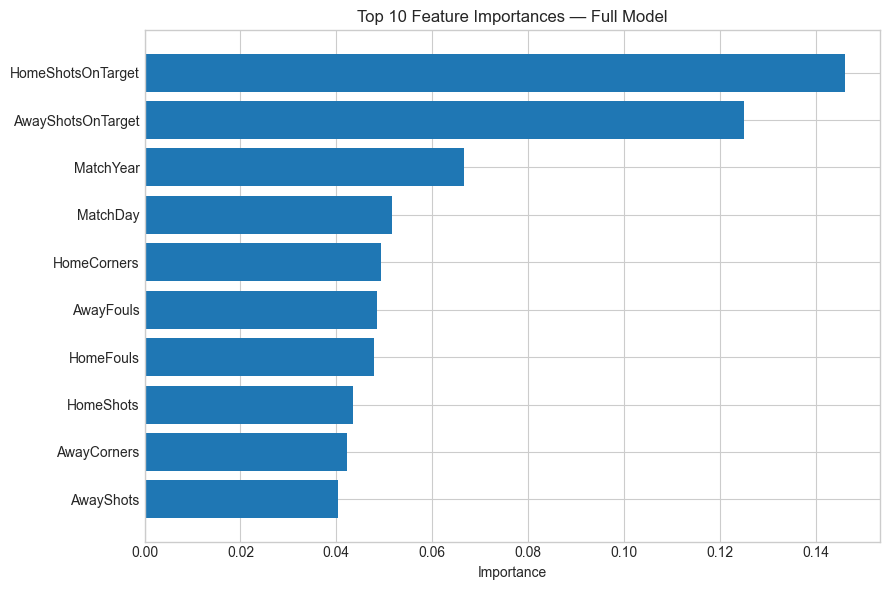


Top Features — Full Model


,Feature,Importance
123,HomeShotsOnTarget,0.146145
124,AwayShotsOnTarget,0.125001
117,MatchYear,0.066626
119,MatchDay,0.051644
125,HomeCorners,0.049369
128,AwayFouls,0.048583
127,HomeFouls,0.047773
121,HomeShots,0.043552
126,AwayCorners,0.042283
122,AwayShots,0.040396


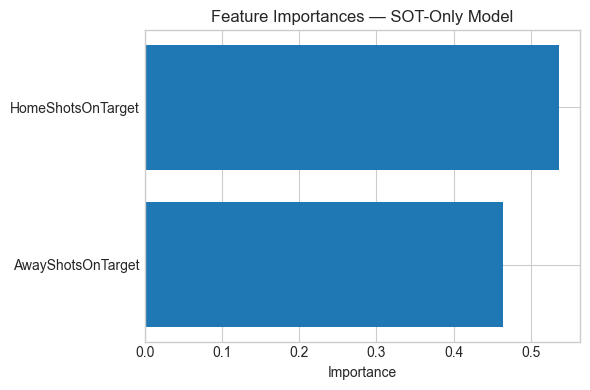


Feature Importances — SOT-Only Model


,Feature,Importance
0,HomeShotsOnTarget,0.536673
1,AwayShotsOnTarget,0.463327


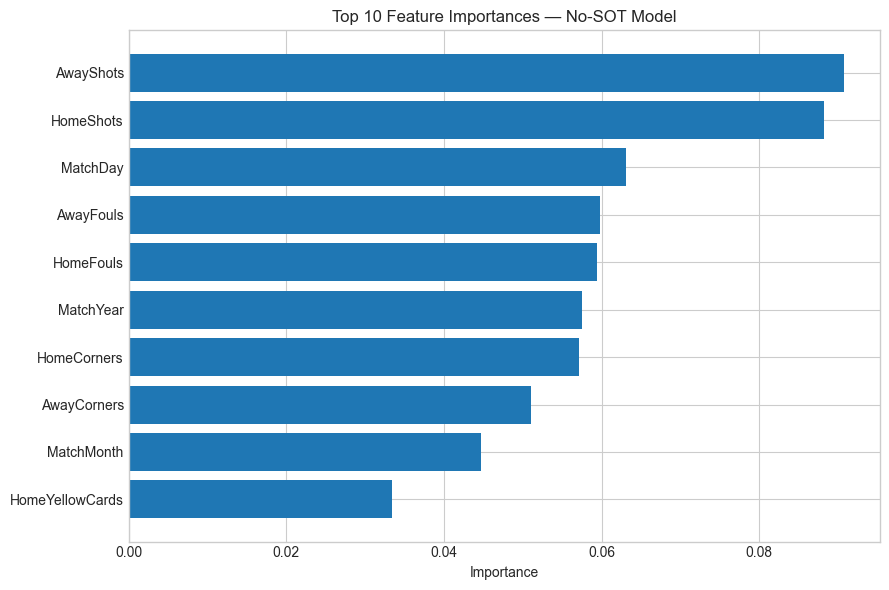


Top Features — No-SOT Model


,Feature,Importance
122,AwayShots,0.090799
121,HomeShots,0.088216
119,MatchDay,0.063115
126,AwayFouls,0.059838
125,HomeFouls,0.059433
117,MatchYear,0.057567
123,HomeCorners,0.057153
124,AwayCorners,0.051050
118,MatchMonth,0.044680
127,HomeYellowCards,0.033368


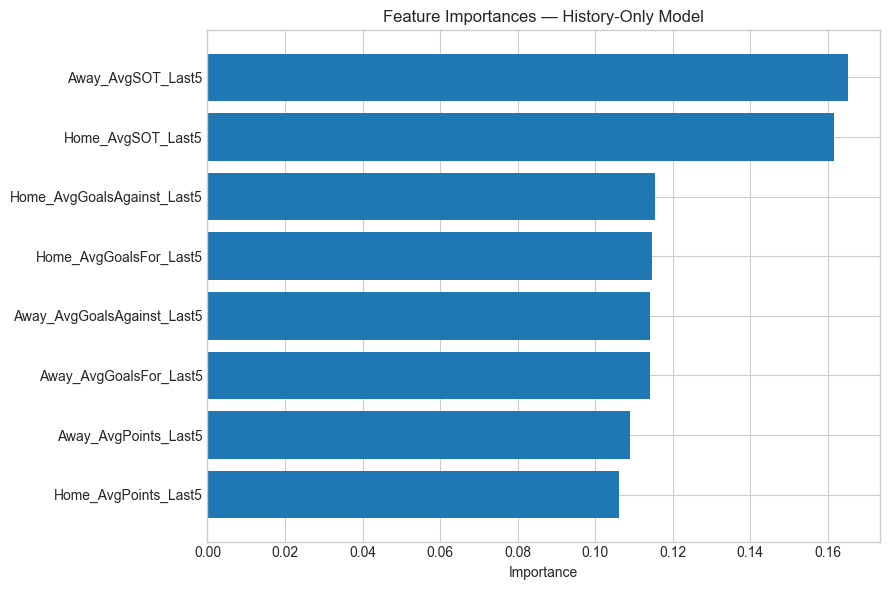


Feature Importances — History-Only Model


,Feature,Importance
6,Away_AvgSOT_Last5,0.165180
2,Home_AvgSOT_Last5,0.161593
1,Home_AvgGoalsAgainst_Last5,0.115371
0,Home_AvgGoalsFor_Last5,0.114590
5,Away_AvgGoalsAgainst_Last5,0.114137
4,Away_AvgGoalsFor_Last5,0.114076
7,Away_AvgPoints_Last5,0.108948
3,Home_AvgPoints_Last5,0.106106


In [29]:
ohe = model_full.named_steps["prep"].named_transformers_["cat"]

# use try-except for compatibility with different sklearn versions
try:
    catNames = ohe.get_feature_names_out()
except TypeError:
    catNames = ohe.get_feature_names_out(ohe.feature_names_in_)

numNames = np.array(numeric_cols_full, dtype=object)

featureNamesFull = np.concatenate([catNames, numNames])
importances_full = model_full.named_steps["rf"].feature_importances_

fi_full = (
    pd.DataFrame({"Feature": featureNamesFull, "Importance": importances_full})
    .sort_values("Importance", ascending=False)
    .head(10)
)
# Plot top 10 feature importances
plt.figure(figsize=(9,6))
plt.barh(fi_full["Feature"][::-1], fi_full["Importance"][::-1])
plt.title("Top 10 Feature Importances — Full Model")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print("\nTop Features — Full Model")
display(fi_full)


# 2) SOT-ONLY MODEL (just two numeric features)

featureNamesSOT = ["HomeShotsOnTarget", "AwayShotsOnTarget"]
importances_sot = model_sot.named_steps["rf"].feature_importances_

fi_sot = pd.DataFrame({
    "Feature": featureNamesSOT,
    "Importance": importances_sot
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(6,4))
plt.barh(fi_sot["Feature"][::-1], fi_sot["Importance"][::-1])
plt.title("Feature Importances — SOT-Only Model")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print("\nFeature Importances — SOT-Only Model")
display(fi_sot)


# 3) NO-SOT MODEL (categorical + numeric excluding SOT)

ohe_nosot = model_no_sot.named_steps["prep"].named_transformers_["cat"]

try:
    catNamesNoSOT = ohe_nosot.get_feature_names_out()
except TypeError:
    catNamesNoSOT = ohe_nosot.get_feature_names_out(ohe_nosot.feature_names_in_)

numNamesNoSOT = np.array(numeric_cols_no_sot, dtype=object)

featureNamesNoSOT = np.concatenate([catNamesNoSOT, numNamesNoSOT])
importances_nosot = model_no_sot.named_steps["rf"].feature_importances_

fi_nosot = (
    pd.DataFrame({"Feature": featureNamesNoSOT, "Importance": importances_nosot})
    .sort_values("Importance", ascending=False)
    .head(10)
)

plt.figure(figsize=(9,6))
plt.barh(fi_nosot["Feature"][::-1], fi_nosot["Importance"][::-1])
plt.title("Top 10 Feature Importances — No-SOT Model")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print("\nTop Features — No-SOT Model")
display(fi_nosot)


# 4) HISTORY-ONLY ROLLING AVERAGE MODEL

history_feature_cols = [
    "Home_AvgGoalsFor_Last5","Home_AvgGoalsAgainst_Last5",
    "Home_AvgSOT_Last5","Home_AvgPoints_Last5",
    "Away_AvgGoalsFor_Last5","Away_AvgGoalsAgainst_Last5",
    "Away_AvgSOT_Last5","Away_AvgPoints_Last5"
]

featureNamesHist = history_feature_cols
importances_hist = model_history.named_steps["rf"].feature_importances_

fi_hist = (
    pd.DataFrame({"Feature": featureNamesHist, "Importance": importances_hist})
    .sort_values("Importance", ascending=False)
)

plt.figure(figsize=(9,6))
plt.barh(fi_hist["Feature"][::-1], fi_hist["Importance"][::-1])
plt.title("Feature Importances — History-Only Model")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

print("\nFeature Importances — History-Only Model")
display(fi_hist)


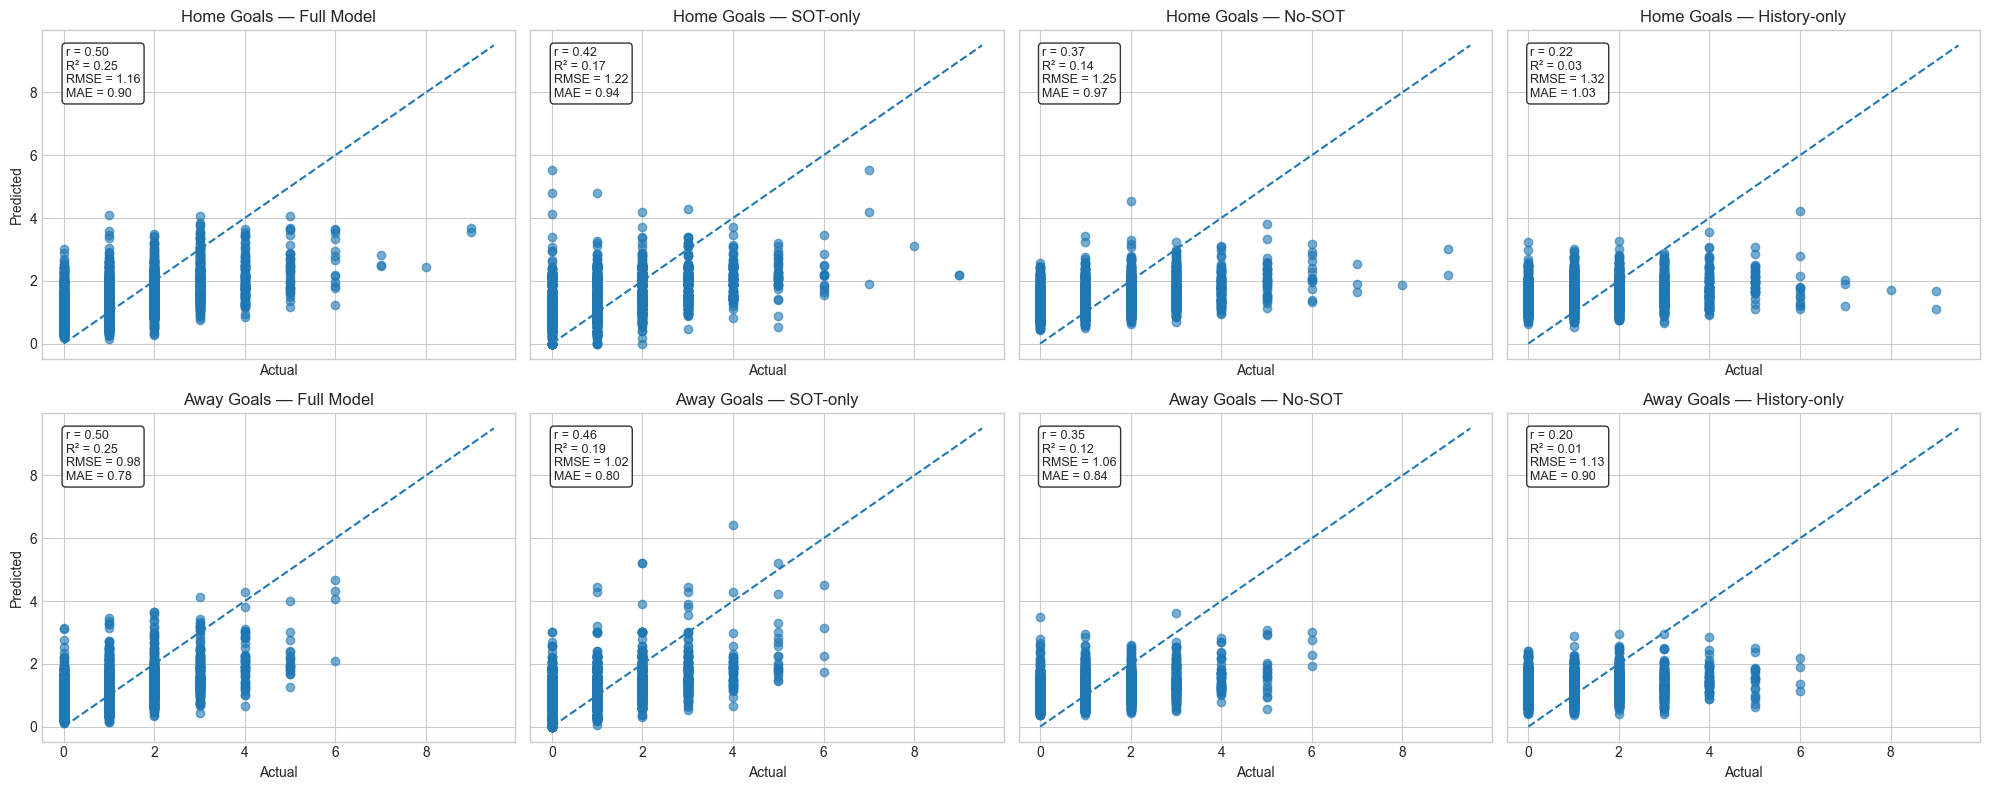

In [30]:
# Predictions on test set
predFullTest   = model_full.predict(SOT_test)
predSotTest    = model_sot.predict(Xs_test)
predNoSotTest  = model_no_sot.predict(Xnosot_test)
predHistTest   = model_history.predict(Xhist_test)

# Scatter Plots: Actual vs Predicted Goals 

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

def add_metrics_box(ax, y_true, y_pred):
    corr = np.corrcoef(y_true, y_pred)[0, 1]
    r2   = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)

    textstr = (
        f"r = {corr:.2f}\n"
        f"R² = {r2:.2f}\n"
        f"RMSE = {rmse:.2f}\n"
        f"MAE = {mae:.2f}"
    )

    ax.text(
        0.05, 0.95, textstr,
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment="top",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
    )

# Common axis limits (include all 4 models)
limHome = max(
    goal_test.iloc[:,0].max(),
    predFullTest[:,0].max(),
    predSotTest[:,0].max(),
    predNoSotTest[:,0].max(),
    predHistTest[:,0].max()
) + 0.5

limAway = max(
    goal_test.iloc[:,1].max(),
    predFullTest[:,1].max(),
    predSotTest[:,1].max(),
    predNoSotTest[:,1].max(),
    predHistTest[:,1].max()
) + 0.5

lim = max(limHome, limAway)

# 2 rows (Home/Away) × 4 columns (Full, SOT, No-SOT, History)
fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharex=True, sharey=True)

#  Home goals 
# Home — Full
axes[0,0].scatter(goal_test.iloc[:,0], predFullTest[:,0], alpha=0.6)
axes[0,0].plot([0,lim],[0,lim], linestyle="--")
axes[0,0].set_title("Home Goals — Full Model")
axes[0,0].set_xlabel("Actual")
axes[0,0].set_ylabel("Predicted")
add_metrics_box(axes[0,0], goal_test.iloc[:,0].values, predFullTest[:,0])

# Home — SOT-only
axes[0,1].scatter(goal_test.iloc[:,0], predSotTest[:,0], alpha=0.6)
axes[0,1].plot([0,lim],[0,lim], linestyle="--")
axes[0,1].set_title("Home Goals — SOT-only")
axes[0,1].set_xlabel("Actual")
add_metrics_box(axes[0,1], goal_test.iloc[:,0].values, predSotTest[:,0])

# Home — No-SOT
axes[0,2].scatter(goal_test.iloc[:,0], predNoSotTest[:,0], alpha=0.6)
axes[0,2].plot([0,lim],[0,lim], linestyle="--")
axes[0,2].set_title("Home Goals — No-SOT")
axes[0,2].set_xlabel("Actual")
add_metrics_box(axes[0,2], goal_test.iloc[:,0].values, predNoSotTest[:,0])

# Home — History-only
axes[0,3].scatter(goal_test.iloc[:,0], predHistTest[:,0], alpha=0.6)
axes[0,3].plot([0,lim],[0,lim], linestyle="--")
axes[0,3].set_title("Home Goals — History-only")
axes[0,3].set_xlabel("Actual")
add_metrics_box(axes[0,3], goal_test.iloc[:,0].values, predHistTest[:,0])

#  Away goals 
# Away — Full
axes[1,0].scatter(goal_test.iloc[:,1], predFullTest[:,1], alpha=0.6)
axes[1,0].plot([0,lim],[0,lim], linestyle="--")
axes[1,0].set_title("Away Goals — Full Model")
axes[1,0].set_xlabel("Actual")
axes[1,0].set_ylabel("Predicted")
add_metrics_box(axes[1,0], goal_test.iloc[:,1].values, predFullTest[:,1])

# Away — SOT-only
axes[1,1].scatter(goal_test.iloc[:,1], predSotTest[:,1], alpha=0.6)
axes[1,1].plot([0,lim],[0,lim], linestyle="--")
axes[1,1].set_title("Away Goals — SOT-only")
axes[1,1].set_xlabel("Actual")
add_metrics_box(axes[1,1], goal_test.iloc[:,1].values, predSotTest[:,1])

# Away — No-SOT
axes[1,2].scatter(goal_test.iloc[:,1], predNoSotTest[:,1], alpha=0.6)
axes[1,2].plot([0,lim],[0,lim], linestyle="--")
axes[1,2].set_title("Away Goals — No-SOT")
axes[1,2].set_xlabel("Actual")
add_metrics_box(axes[1,2], goal_test.iloc[:,1].values, predNoSotTest[:,1])

# Away — History-only
axes[1,3].scatter(goal_test.iloc[:,1], predHistTest[:,1], alpha=0.6)
axes[1,3].plot([0,lim],[0,lim], linestyle="--")
axes[1,3].set_title("Away Goals — History-only")
axes[1,3].set_xlabel("Actual")
add_metrics_box(axes[1,3], goal_test.iloc[:,1].values, predHistTest[:,1])

plt.tight_layout()
plt.show()


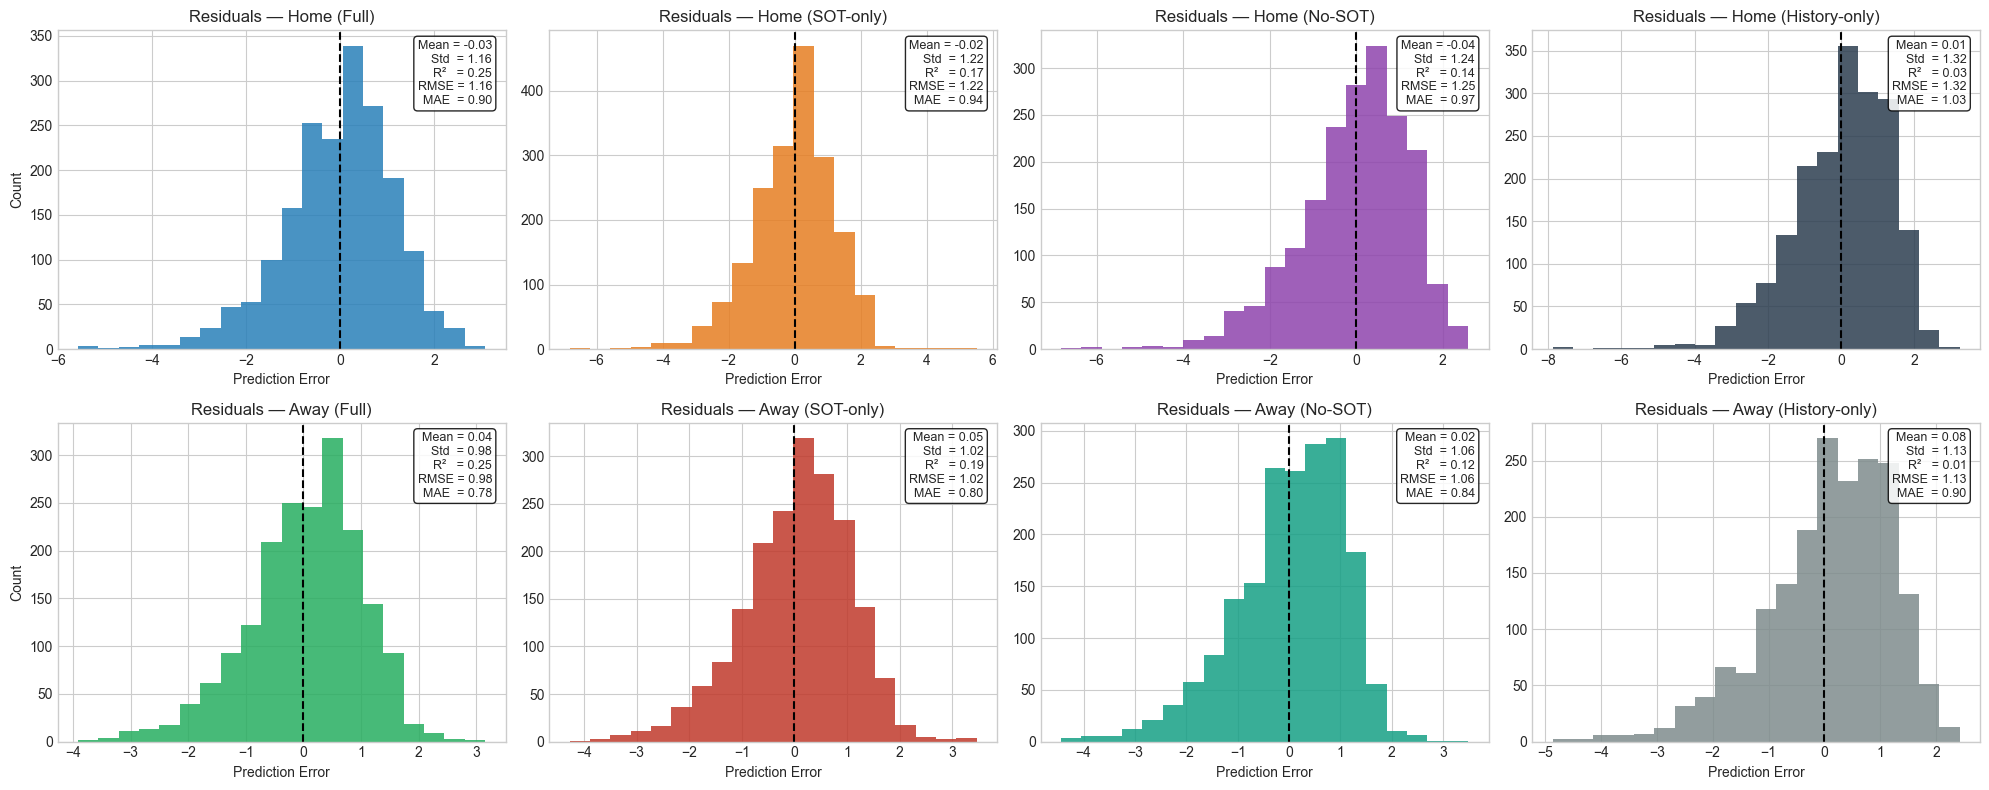

In [31]:
resHomeFull   = predFullTest[:,0]  - goal_test.iloc[:,0].values
resAwayFull   = predFullTest[:,1]  - goal_test.iloc[:,1].values

resHomeSot    = predSotTest[:,0]   - goal_test.iloc[:,0].values
resAwaySot    = predSotTest[:,1]   - goal_test.iloc[:,1].values

resHomeNoSot  = predNoSotTest[:,0] - goal_test.iloc[:,0].values
resAwayNoSot  = predNoSotTest[:,1] - goal_test.iloc[:,1].values

# History-only residuals
resHomeHist   = predHistTest[:,0]  - goal_test.iloc[:,0].values
resAwayHist   = predHistTest[:,1]  - goal_test.iloc[:,1].values

y_home = goal_test.iloc[:,0].values
y_away = goal_test.iloc[:,1].values


# Annotation box for each subplot
def annotate_stats(ax, y_true, y_pred, residuals):
    mean_err = np.mean(residuals)
    std_err  = np.std(residuals)

    r2   = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)

    textstr = (
        f"Mean = {mean_err:.2f}\n"
        f"Std  = {std_err:.2f}\n"
        f"R²   = {r2:.2f}\n"
        f"RMSE = {rmse:.2f}\n"
        f"MAE  = {mae:.2f}"
    )

    ax.text(
        0.97, 0.97, textstr,
        transform=ax.transAxes,
        ha="right", va="top",
        fontsize=9,
        bbox=dict(facecolor="white", alpha=0.85, boxstyle="round,pad=0.3")
    )


# Residual plot grid (2 rows × 4 columns)
fig, axes = plt.subplots(2, 4, figsize=(20, 8))

# ------------ HOME GOALS ------------
# Full
axes[0,0].hist(resHomeFull, bins=20, color="#2980b9", alpha=0.85)
axes[0,0].axvline(0, linestyle="--", color="black")
axes[0,0].set_title("Residuals — Home (Full)")
axes[0,0].set_xlabel("Prediction Error")
axes[0,0].set_ylabel("Count")
annotate_stats(axes[0,0], y_home, predFullTest[:,0], resHomeFull)

# SOT-only
axes[0,1].hist(resHomeSot, bins=20, color="#e67e22", alpha=0.85)
axes[0,1].axvline(0, linestyle="--", color="black")
axes[0,1].set_title("Residuals — Home (SOT-only)")
axes[0,1].set_xlabel("Prediction Error")
annotate_stats(axes[0,1], y_home, predSotTest[:,0], resHomeSot)

# No-SOT
axes[0,2].hist(resHomeNoSot, bins=20, color="#8e44ad", alpha=0.85)
axes[0,2].axvline(0, linestyle="--", color="black")
axes[0,2].set_title("Residuals — Home (No-SOT)")
axes[0,2].set_xlabel("Prediction Error")
annotate_stats(axes[0,2], y_home, predNoSotTest[:,0], resHomeNoSot)

# History-only
axes[0,3].hist(resHomeHist, bins=20, color="#2c3e50", alpha=0.85)
axes[0,3].axvline(0, linestyle="--", color="black")
axes[0,3].set_title("Residuals — Home (History-only)")
axes[0,3].set_xlabel("Prediction Error")
annotate_stats(axes[0,3], y_home, predHistTest[:,0], resHomeHist)


# ------------ AWAY GOALS ------------
# Full
axes[1,0].hist(resAwayFull, bins=20, color="#27ae60", alpha=0.85)
axes[1,0].axvline(0, linestyle="--", color="black")
axes[1,0].set_title("Residuals — Away (Full)")
axes[1,0].set_xlabel("Prediction Error")
axes[1,0].set_ylabel("Count")
annotate_stats(axes[1,0], y_away, predFullTest[:,1], resAwayFull)

# SOT-only
axes[1,1].hist(resAwaySot, bins=20, color="#c0392b", alpha=0.85)
axes[1,1].axvline(0, linestyle="--", color="black")
axes[1,1].set_title("Residuals — Away (SOT-only)")
axes[1,1].set_xlabel("Prediction Error")
annotate_stats(axes[1,1], y_away, predSotTest[:,1], resAwaySot)

# No-SOT
axes[1,2].hist(resAwayNoSot, bins=20, color="#16a085", alpha=0.85)
axes[1,2].axvline(0, linestyle="--", color="black")
axes[1,2].set_title("Residuals — Away (No-SOT)")
axes[1,2].set_xlabel("Prediction Error")
annotate_stats(axes[1,2], y_away, predNoSotTest[:,1], resAwayNoSot)

# History-only
axes[1,3].hist(resAwayHist, bins=20, color="#7f8c8d", alpha=0.85)
axes[1,3].axvline(0, linestyle="--", color="black")
axes[1,3].set_title("Residuals — Away (History-only)")
axes[1,3].set_xlabel("Prediction Error")
annotate_stats(axes[1,3], y_away, predHistTest[:,1], resAwayHist)

plt.tight_layout()
plt.show()

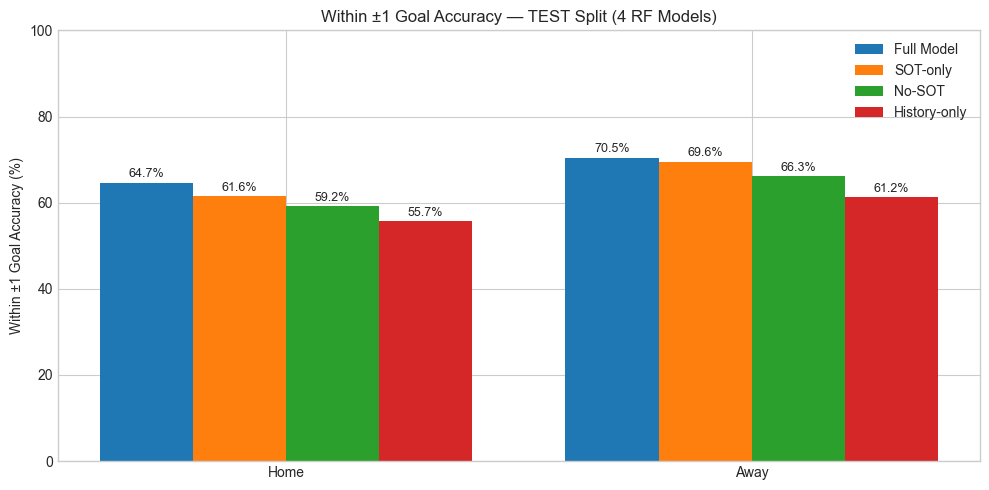

In [32]:
# Within one plus 1 Accuracy — TEST Split

# Existing errors
errHomeFull  = np.abs(goal_test.iloc[:,0].values - predFullTest[:,0])
errAwayFull  = np.abs(goal_test.iloc[:,1].values - predFullTest[:,1])
errHomeSot   = np.abs(goal_test.iloc[:,0].values - predSotTest[:,0])
errAwaySot   = np.abs(goal_test.iloc[:,1].values - predSotTest[:,1])
errHomeNoSot = np.abs(goal_test.iloc[:,0].values - predNoSotTest[:,0])
errAwayNoSot = np.abs(goal_test.iloc[:,1].values - predNoSotTest[:,1])

# NEW: History-only errors
errHomeHist  = np.abs(goal_test.iloc[:,0].values - predHistTest[:,0])
errAwayHist  = np.abs(goal_test.iloc[:,1].values - predHistTest[:,1])

def rate_within1(arr): 
    return 100.0 * np.mean(arr <= 1)

labels = ["Home", "Away"]
x = np.arange(len(labels))

# 4 models → make bars a bit thinner
width = 0.2

w1_full   = [rate_within1(errHomeFull),   rate_within1(errAwayFull)]
w1_sot    = [rate_within1(errHomeSot),    rate_within1(errAwaySot)]
w1_nosot  = [rate_within1(errHomeNoSot),  rate_within1(errAwayNoSot)]
w1_hist   = [rate_within1(errHomeHist),   rate_within1(errAwayHist)]

def add_bar_labels(ax, bars):
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2., height + 0.5,
            f"{height:.1f}%",
            ha="center", va="bottom", fontsize=9
        )

plt.figure(figsize=(10,5))
bars1 = plt.bar(x - 1.5*width, w1_full,  width, label="Full Model")
bars2 = plt.bar(x - 0.5*width, w1_sot,   width, label="SOT-only")
bars3 = plt.bar(x + 0.5*width, w1_nosot, width, label="No-SOT")
bars4 = plt.bar(x + 1.5*width, w1_hist,  width, label="History-only")

# Customize plot 
plt.xticks(x, labels)
plt.ylabel("Within ±1 Goal Accuracy (%)")
plt.title("Within ±1 Goal Accuracy — TEST Split (4 RF Models)")
plt.legend()

ax = plt.gca()
add_bar_labels(ax, bars1)
add_bar_labels(ax, bars2)
add_bar_labels(ax, bars3)
add_bar_labels(ax, bars4)

plt.ylim(0, 100)
plt.tight_layout()
plt.show()


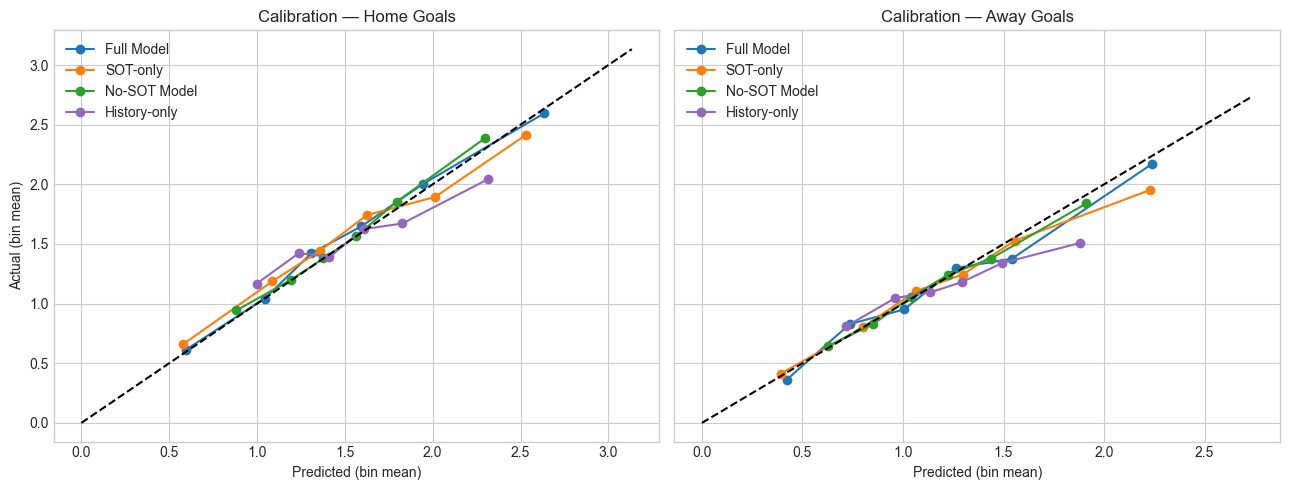

In [33]:
# 5) Calibration Plots — Are predictions well-calibrated?
#    (Bin predictions and compare predicted vs actual means)
def calibration_points(y_true, y_pred, n_bins=6):
    y_pred = np.clip(y_pred, 0, None)
    bins = np.quantile(y_pred, np.linspace(0,1,n_bins+1))

    bins = np.unique(bins)
    if len(bins) < 3:
        bins = np.linspace(y_pred.min(), y_pred.max(), n_bins+1)

    inds = np.digitize(y_pred, bins[1:-1], right=True)

    dfc = pd.DataFrame({"pred": y_pred, "act": y_true, "bin": inds})
    pts = dfc.groupby("bin").agg(
        pred_mean=("pred","mean"),
        act_mean=("act","mean")
    ).dropna()

    return pts


# Plot (Home + Away) with all 4 models
fig, axes = plt.subplots(1, 2, figsize=(13,5), sharey=True)

# ------------------ HOME ------------------
ptsFullHome   = calibration_points(goal_test.iloc[:,0].values, predFullTest[:,0])
ptsSotHome    = calibration_points(goal_test.iloc[:,0].values, predSotTest[:,0])
ptsNoSotHome  = calibration_points(goal_test.iloc[:,0].values, predNoSotTest[:,0])
ptsHistHome   = calibration_points(goal_test.iloc[:,0].values, predHistTest[:,0])

axes[0].plot(ptsFullHome["pred_mean"],  ptsFullHome["act_mean"],
             marker="o", label="Full Model",     color="#1f77b4")
axes[0].plot(ptsSotHome["pred_mean"],   ptsSotHome["act_mean"],
             marker="o", label="SOT-only",       color="#ff7f0e")
axes[0].plot(ptsNoSotHome["pred_mean"], ptsNoSotHome["act_mean"],
             marker="o", label="No-SOT Model",   color="#2ca02c")
axes[0].plot(ptsHistHome["pred_mean"],  ptsHistHome["act_mean"],
             marker="o", label="History-only",   color="#9467bd")

mx = max(
    ptsFullHome["pred_mean"].max(),   ptsSotHome["pred_mean"].max(),
    ptsNoSotHome["pred_mean"].max(),  ptsHistHome["pred_mean"].max(),
    ptsFullHome["act_mean"].max(),    ptsSotHome["act_mean"].max(),
    ptsNoSotHome["act_mean"].max(),   ptsHistHome["act_mean"].max()
) + 0.5

axes[0].plot([0,mx],[0,mx], linestyle="--", color="black")
axes[0].set_title("Calibration — Home Goals")
axes[0].set_xlabel("Predicted (bin mean)")
axes[0].set_ylabel("Actual (bin mean)")
axes[0].legend()


# ------------------ AWAY ------------------
ptsFullAway   = calibration_points(goal_test.iloc[:,1].values, predFullTest[:,1])
ptsSotAway    = calibration_points(goal_test.iloc[:,1].values, predSotTest[:,1])
ptsNoSotAway  = calibration_points(goal_test.iloc[:,1].values, predNoSotTest[:,1])
ptsHistAway   = calibration_points(goal_test.iloc[:,1].values, predHistTest[:,1])

axes[1].plot(ptsFullAway["pred_mean"],  ptsFullAway["act_mean"],
             marker="o", label="Full Model",     color="#1f77b4")
axes[1].plot(ptsSotAway["pred_mean"],   ptsSotAway["act_mean"],
             marker="o", label="SOT-only",       color="#ff7f0e")
axes[1].plot(ptsNoSotAway["pred_mean"], ptsNoSotAway["act_mean"],
             marker="o", label="No-SOT Model",   color="#2ca02c")
axes[1].plot(ptsHistAway["pred_mean"],  ptsHistAway["act_mean"],
             marker="o", label="History-only",   color="#9467bd")

mx = max(
    ptsFullAway["pred_mean"].max(),   ptsSotAway["pred_mean"].max(),
    ptsNoSotAway["pred_mean"].max(),  ptsHistAway["pred_mean"].max(),
    ptsFullAway["act_mean"].max(),    ptsSotAway["act_mean"].max(),
    ptsNoSotAway["act_mean"].max(),   ptsHistAway["act_mean"].max()
) + 0.5

axes[1].plot([0,mx],[0,mx], linestyle="--", color="black")
axes[1].set_title("Calibration — Away Goals")
axes[1].set_xlabel("Predicted (bin mean)")
axes[1].legend()

plt.tight_layout()
plt.show()

# - Models closer to the diagonal are better calibrated.
# - Compare how History-only vs Full behave, especially in high-goal bins.


## Logistic Regression
#### It estimates the probability of each result based on features like **shots on target** and **fouls**.  
#### This **baseline model** for predicting football match outcomes before applying advanced methods.

### Lets create a target variable
#### FullTimeResult: H = Home Win, D = Draw, A = Away Win
#### We have to convert categorical results to numerical form for model training

In [34]:
eplData["MatchResult"] = eplData["FullTimeResult"].map({"H": 2, "D": 1, "A": 0})
# Display the first few rows of the MatchResult column
print(eplData[["FullTimeResult", "MatchResult"]].head())
# Drop rows with missing target
# eplDataMissingValue = eplData.dropna(subset=["MatchResult"])
# checked for missing values in MatchResult column, none found so ignoring the code line
# Basic match context features
eplData["MatchDate"] = pd.to_datetime(eplData["MatchDate"], errors="coerce")
eplData = eplData.dropna(subset=["MatchDate"]).copy()

eplData["MatchYear"]  = eplData["MatchDate"].dt.year
eplData["MatchMonth"] = eplData["MatchDate"].dt.month
eplData["MatchDoW"]   = eplData["MatchDate"].dt.dayofweek


  FullTimeResult  MatchResult
0              H            2
1              H            2
2              A            0
3              D            1
4              H            2


#### Lets create a feature selection to make model known about the column like shots, fouls, cards for predicting the match result

In [35]:
categorical_cols = ["HomeTeam", "AwayTeam"]

numeric_cols = [
    "HomeShotsOnTarget", "AwayShotsOnTarget",
    "HomeCorners", "AwayCorners",
    "HomeFouls", "AwayFouls",
    "HomeYellowCards", "AwayYellowCards",
    "MatchYear", "MatchMonth", "MatchDoW"
]
# Prepare feature DataFrame and target Series

eplLogData = eplData[categorical_cols + numeric_cols].copy()
eplMatchResult = eplData["MatchResult"].astype(int)

# Display samples of features and target
print("\nFeature sample:")
display(eplLogData.head())
print("\nTarget sample:")
print(eplMatchResult.head())


Feature sample:


,HomeTeam,AwayTeam,HomeShotsOnTarget,AwayShotsOnTarget,HomeCorners,AwayCorners,HomeFouls,AwayFouls,HomeYellowCards,AwayYellowCards,MatchYear,MatchMonth,MatchDoW
0,Charlton,Man City,14,4,6,6,13,12,1,2,2000,8,5
1,Chelsea,West Ham,10,5,7,7,19,14,1,2,2000,8,5
2,Coventry,Middlesbrough,3,9,8,4,15,21,5,3,2000,8,5
3,Derby,Southampton,4,6,5,8,11,13,1,1,2000,8,5
4,Leeds,Everton,8,6,6,4,21,20,1,3,2000,8,5



Target sample:
0    2
1    2
2    0
3    1
4    2
Name: MatchResult, dtype: int64


### Split the data for Train and Test 

In [36]:
eplLogDatatrain, eplLogDatatest, eplMatchResulttrain, eplMatchResulttest = train_test_split(
    eplLogData, eplMatchResult,
    test_size=0.2,
    random_state=42,
    stratify=eplMatchResult
)
# Display train-test split sizes
print(f"\nTraining samples: {len(eplMatchResulttrain)}")
print(f"Test samples: {len(eplMatchResulttest)}")


Training samples: 7504
Test samples: 1876


### Logistic Regression Model
##### Parameters `multi_class="multinomial"` and `solver="lbfgs"` I have used this parameters to handle multiple result categories efficiently

In [37]:
categorical_transformer = OneHotEncoder(handle_unknown="ignore")

# Numeric features: impute missing values and scale
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        # ("cat", categorical_transformer, categorical_cols),
        ("num", numeric_transformer, numeric_cols),
    ]
)

# Logistic Regression Classifier
log_clf = LogisticRegression(
    multi_class="multinomial",
    solver="lbfgs",
    max_iter=1000,
    class_weight="balanced",
    n_jobs=-1
)

logistic_pipeline = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf",  log_clf)
])



### Fitting Logistic Regression Model


In [38]:
warnings.filterwarnings("ignore")

# Train logistic regression model
logistic_pipeline.fit(eplLogDatatrain, eplMatchResulttrain)
y_pred = logistic_pipeline.predict(eplLogDatatest)
y_proba = logistic_pipeline.predict_proba(eplLogDatatest)  # for later use (e.g. calibration)

acc        = accuracy_score(eplMatchResulttest, y_pred)
bal_acc    = balanced_accuracy_score(eplMatchResulttest, y_pred)
f1_macro   = f1_score(eplMatchResulttest, y_pred, average="macro")

### Evaluation Results
print(f"\n=== Logistic Regression (Multinomial) — Match Result (W/D/L) ===")
print(f"Accuracy:           {acc*100:.2f}%")
print(f"Balanced Accuracy:  {bal_acc*100:.2f}%")
print(f"Macro F1-score:     {f1_macro:.3f}\n")


print("Classification Report:")
print(classification_report(
    eplMatchResulttest,
    y_pred,
    target_names=["Away Win (0)", "Draw (1)", "Home Win (2)"]
))

prep = logistic_pipeline.named_steps["prep"]

# Transform training data (design matrix for statsmodels)
X_design = prep.transform(eplLogDatatrain)

# If it's sparse (OneHotEncoder), convert to dense
if sp.issparse(X_design):
    X_design = X_design.toarray()

# Getting feature names from ColumnTransformer
feature_names = prep.get_feature_names_out()

print("X_design shape:", X_design.shape)
print("Number of feature names:", len(feature_names))

# Build DataFrame for exog (explanatory variables)
X_df = pd.DataFrame(X_design, columns=feature_names)

# Adding intercept (this is X_with_intercept)
X_df = sm.add_constant(X_df, has_constant="add")

# Target (endog), ensure 1D int and aligned index
y_train = pd.Series(eplMatchResulttrain).astype(int)

# Reset indices to avoid alignment issues
X_df    = X_df.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)

# ===== 2. Fit multinomial logit in statsmodels =====
mnlogit_model   = sm.MNLogit(y_train, X_df)
mnlogit_results = mnlogit_model.fit(maxiter=200, disp=False)

print(mnlogit_results.summary())


=== Logistic Regression (Multinomial) — Match Result (W/D/L) ===
Accuracy:           53.14%
Balanced Accuracy:  50.56%
Macro F1-score:     0.501

Classification Report:
              precision    recall  f1-score   support

Away Win (0)       0.53      0.62      0.57       554
    Draw (1)       0.31      0.30      0.30       462
Home Win (2)       0.67      0.60      0.63       860

    accuracy                           0.53      1876
   macro avg       0.50      0.51      0.50      1876
weighted avg       0.54      0.53      0.53      1876

X_design shape: (7504, 11)
Number of feature names: 11
                          MNLogit Regression Results                          
Dep. Variable:            MatchResult   No. Observations:                 7504
Model:                        MNLogit   Df Residuals:                     7480
Method:                           MLE   Df Model:                           22
Date:                Mon, 05 Oct 2026   Pseudo R-squ.:                  0.1305

### Visualization of Results as Plots 

##### Confusion Matrix

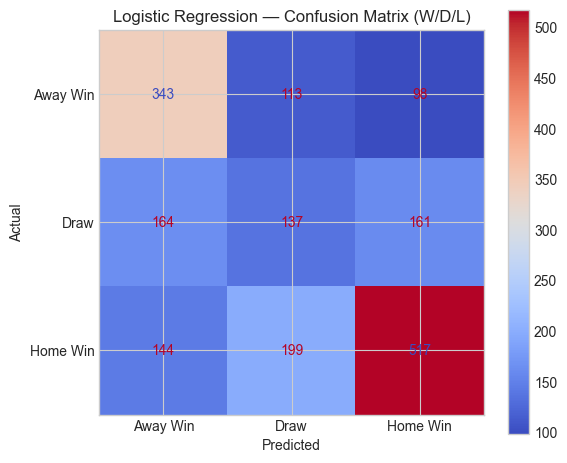

In [39]:
# Confusion Matrix Plot
cm = confusion_matrix(eplMatchResulttest, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Away Win", "Draw", "Home Win"]
)
# Plot confusion matrix
fig, ax = plt.subplots(figsize=(6,5))
disp.plot(cmap="coolwarm", values_format="d", ax=ax)
plt.title("Logistic Regression — Confusion Matrix (W/D/L)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


##### Coefficient interpretation (feature influence)


Top numeric features influencing match result (by max |coefficient|):


,Away Win (0),Draw (1),Home Win (2),MaxAbsEffect
num__HomeShotsOnTarget,-0.532876,-0.062961,0.595837,0.595837
num__AwayShotsOnTarget,0.581240,-0.065414,-0.515826,0.581240
num__HomeCorners,0.130022,0.051945,-0.181968,0.181968
num__AwayCorners,-0.175628,0.020829,0.154799,0.175628
num__HomeYellowCards,0.084676,0.043630,-0.128306,0.128306
num__MatchYear,0.034103,-0.090198,0.056096,0.090198
num__AwayYellowCards,-0.059297,0.066410,-0.007113,0.066410
num__AwayFouls,-0.025999,0.029381,-0.003383,0.029381
num__MatchMonth,0.017950,0.003768,-0.021719,0.021719
num__HomeFouls,-0.017018,0.010696,0.006322,0.017018


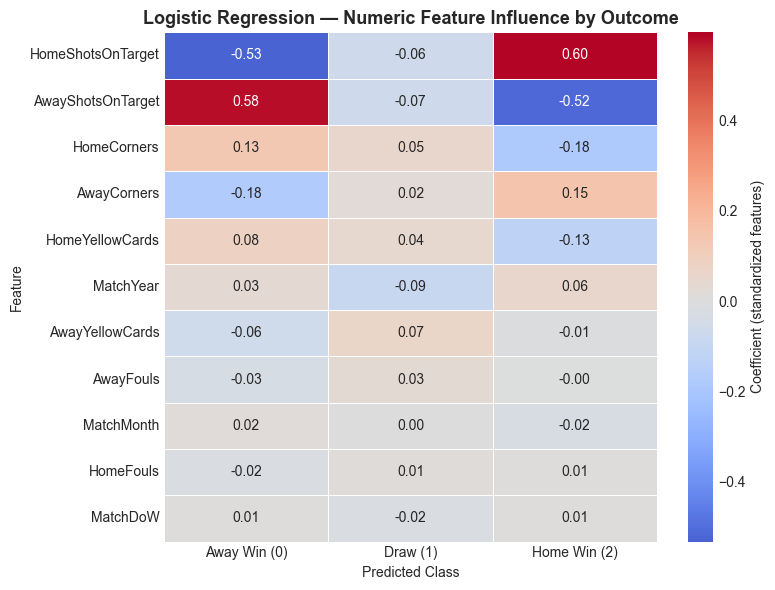

In [40]:
# Extract trained logistic model and preprocessor
clf_fitted  = logistic_pipeline.named_steps["clf"]
prep_fitted = logistic_pipeline.named_steps["prep"]

# Get all directly from the fitted ColumnTransformer
feature_names = prep_fitted.get_feature_names_out()

# Coefficient matrix: shape (n_classes, n_features)
coef_matrix = clf_fitted.coef_

# Build full coefficient DataFrame
coef_df = pd.DataFrame(
    coef_matrix.T,
    columns=["Away Win (0)", "Draw (1)", "Home Win (2)"],
    index=feature_names
)


# numeric features 
numeric_mask = pd.Series(feature_names).str.startswith("num__")
numeric_feature_names = pd.Series(feature_names)[numeric_mask].values

coef_numeric = coef_df.loc[numeric_feature_names].copy()
coef_numeric["MaxAbsEffect"] = coef_numeric.abs().max(axis=1)
coef_numeric_sorted = coef_numeric.sort_values("MaxAbsEffect", ascending=False)

print("\nTop numeric features influencing match result (by max |coefficient|):")
display(coef_numeric_sorted)

# Clean up the feature names for plotting (remove 'num__' prefix)
coef_numeric_sorted_plot = coef_numeric_sorted.copy()
coef_numeric_sorted_plot.index = coef_numeric_sorted_plot.index.str.replace("^num__", "", regex=True)

# Heatmap for numeric features
plt.figure(figsize=(8, 6))
sns.heatmap(
    coef_numeric_sorted_plot.drop(columns="MaxAbsEffect"),
    annot=True, fmt=".2f",
    cmap="coolwarm", center=0,
    linewidths=0.5, linecolor="white",
    cbar_kws={"label": "Coefficient (standardized features)"}
)
plt.title("Logistic Regression — Numeric Feature Influence by Outcome", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Class")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()



=== Influence on Match Result (Home Win vs Others) ===


,Feature,Coefficient,Effect
0,num__HomeShotsOnTarget,0.595837,Increases chance of Home Win
3,num__AwayCorners,0.154799,Increases chance of Home Win
8,num__MatchYear,0.056096,Increases chance of Home Win
10,num__MatchDoW,0.008626,Increases chance of Home Win
4,num__HomeFouls,0.006322,Increases chance of Home Win
5,num__AwayFouls,-0.003383,Decreases chance of Home Win
7,num__AwayYellowCards,-0.007113,Decreases chance of Home Win
9,num__MatchMonth,-0.021719,Decreases chance of Home Win
6,num__HomeYellowCards,-0.128306,Decreases chance of Home Win
2,num__HomeCorners,-0.181968,Decreases chance of Home Win


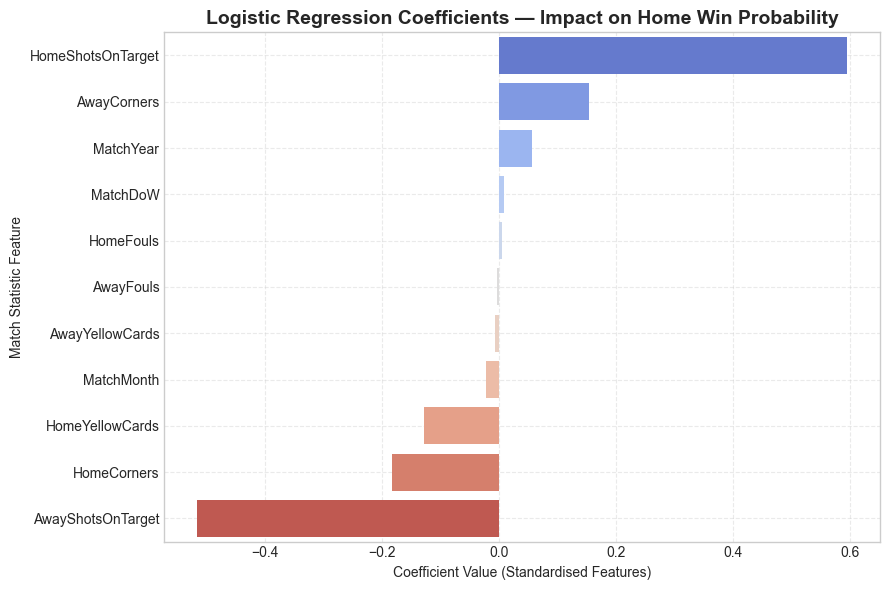

In [41]:
# Extract fitted model + preprocessor
clf_fitted  = logistic_pipeline.named_steps["clf"]
prep_fitted = logistic_pipeline.named_steps["prep"]

# Get correct feature names directly from ColumnTransformer
feature_names = prep_fitted.get_feature_names_out()

# Build coefficient DataFrame
# coef_: shape = (3 classes, n_features)
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": clf_fitted.coef_[2]  # class 2 = Home Win
})

coef_df["Effect"] = np.where(
    coef_df["Coefficient"] > 0,
    "Increases chance of Home Win",
    "Decreases chance of Home Win"
)

print("\n=== Influence on Match Result (Home Win vs Others) ===")
display(coef_df.sort_values("Coefficient", ascending=False))

# = Clean feature names for plotting
coef_df_plot = coef_df.copy()
coef_df_plot["Feature"] = (
    coef_df_plot["Feature"]
    .str.replace("^num__", "", regex=True)
    .str.replace("^cat__", "", regex=True)
)

# numeric features for barplot
numeric_mask = coef_df_plot["Feature"].isin([
    "HomeShotsOnTarget", "AwayShotsOnTarget",
    "HomeCorners", "AwayCorners",
    "HomeFouls", "AwayFouls",
    "HomeYellowCards", "AwayYellowCards",
    "MatchYear", "MatchMonth", "MatchDoW"
])

coef_df_numeric = coef_df_plot[numeric_mask].sort_values("Coefficient", ascending=False)

# Barplot of coefficients
plt.figure(figsize=(9, 6))
sns.barplot(
    x="Coefficient",
    y="Feature",
    data=coef_df_numeric,
    palette="coolwarm"
)
plt.title("Logistic Regression Coefficients — Impact on Home Win Probability",
          fontsize=14, fontweight="bold")
plt.xlabel("Coefficient Value (Standardised Features)")
plt.ylabel("Match Statistic Feature")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


##### Positive (red): increases the log-odds (likelihood) of that class.
##### Negative (blue): decreases it.
##### Bigger magnitude = stronger effect.

Coefficient matrix (first 10 features):


,Away Win,Draw,Home Win
HomeShotsOnTarget,-0.532876,-0.062961,0.595837
AwayShotsOnTarget,0.581240,-0.065414,-0.515826
HomeCorners,0.130022,0.051945,-0.181968
AwayCorners,-0.175628,0.020829,0.154799
HomeFouls,-0.017018,0.010696,0.006322
AwayFouls,-0.025999,0.029381,-0.003383
HomeYellowCards,0.084676,0.043630,-0.128306
AwayYellowCards,-0.059297,0.066410,-0.007113
MatchYear,0.034103,-0.090198,0.056096
MatchMonth,0.017950,0.003768,-0.021719


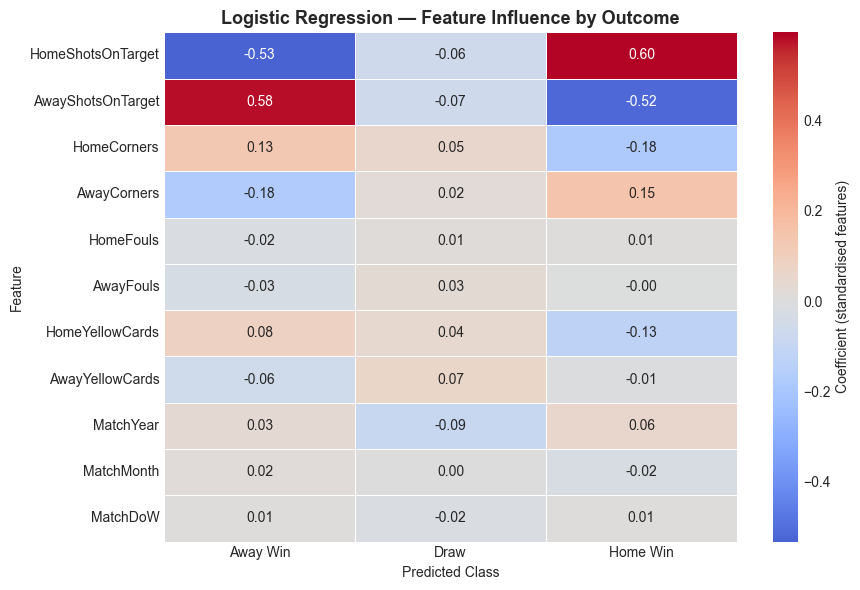

In [42]:
# Extract fitted model + preprocessor
clf_fitted  = logistic_pipeline.named_steps["clf"]
prep_fitted = logistic_pipeline.named_steps["prep"]

# actual feature names after preprocessing
feature_names = prep_fitted.get_feature_names_out()

#  Build coefficient DataFrame for all classes
coef_df = pd.DataFrame(
    clf_fitted.coef_,       # rows = classes
    columns=feature_names,  # columns = features
    index=["Away Win", "Draw", "Home Win"]
).T  # transpose so features are rows

coef_df.index = (
    coef_df.index
    .str.replace("^num__", "", regex=True)
    .str.replace("^cat__", "", regex=True)
)

print("Coefficient matrix (first 10 features):")
display(coef_df.head(10))

#  Focus only on numeric match stats
numeric_features = [
    "HomeShotsOnTarget", "AwayShotsOnTarget",
    "HomeCorners", "AwayCorners",
    "HomeFouls", "AwayFouls",
    "HomeYellowCards", "AwayYellowCards",
    "MatchYear", "MatchMonth", "MatchDoW"
]

mask = coef_df.index.isin(numeric_features)
coef_df_plot = coef_df[mask].copy()

# Heatmap of feature influence by outcome
plt.figure(figsize=(9, 6))
sns.heatmap(
    coef_df_plot,
    annot=True, fmt=".2f",
    cmap="coolwarm", center=0,
    linewidths=0.5, linecolor="white",
    cbar_kws={"label": "Coefficient (standardised features)"}
)
plt.title("Logistic Regression — Feature Influence by Outcome", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Class")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


##### Colors show direction and strength of each feature’s impact on the predicted outcome: red = increases probability, blue = decreases probability and (≈ ±0.5) show strong influence mainly shots on target

#### This is used to classify football match outcomes like **Home Win**, **Draw**, **Away Win** based on key match statistics like shots, fouls, and corners. It provides a baseline model that reveals how different game features influence the probability of each result.

## XGBoost Classifier

#### To improve the model performance we have to modify the colums and update as per we needed 

##### Lets sort the thing that we commonly use 
##### MatchDate is datetime + sort

In [43]:
# Final sorting of eplData by Season and MatchDate
eplData["MatchDate"] = pd.to_datetime(eplData["MatchDate"])
eplData = eplData.sort_values(["Season", "MatchDate"]).reset_index(drop=True)

# Display the first few rows of the final sorted DataFrame
print("Final sorted EPL Data:")
display(eplData.head(10)
    .style.set_table_styles([
        {"selector": "th", "props": [("background-color", "#2c3e50"), ("color", "white"), ("font-weight", "bold")]}
    ])
)

Final sorted EPL Data:


,Season,MatchDate,HomeTeam,AwayTeam,FullTimeHomeGoals,FullTimeAwayGoals,FullTimeResult,HalfTimeHomeGoals,HalfTimeAwayGoals,HalfTimeResult,HomeShots,AwayShots,HomeShotsOnTarget,AwayShotsOnTarget,HomeCorners,AwayCorners,HomeFouls,AwayFouls,HomeYellowCards,AwayYellowCards,HomeRedCards,AwayRedCards,scoredGoal,targetShot,ShotsOnTarget_Range,MatchYear,MatchMonth,MatchDay,MatchDoW,Home_AvgGoalsFor_Last5,Home_AvgGoalsAgainst_Last5,Home_AvgSOT_Last5,Home_AvgPoints_Last5,Away_AvgGoalsFor_Last5,Away_AvgGoalsAgainst_Last5,Away_AvgSOT_Last5,Away_AvgPoints_Last5,MatchResult
0,2000/01,2000-08-19 00:00:00,Charlton,Man City,4,0,H,2,0,H,17,8,14,4,6,6,13,12,1,2,0,0,4.000000,18.000000,18-20,2000,8,19,5,nan,nan,nan,nan,nan,nan,nan,nan,2
1,2000/01,2000-08-19 00:00:00,Chelsea,West Ham,4,2,H,1,0,H,17,12,10,5,7,7,19,14,1,2,0,0,6.000000,15.000000,15,2000,8,19,5,nan,nan,nan,nan,nan,nan,nan,nan,2
2,2000/01,2000-08-19 00:00:00,Coventry,Middlesbrough,1,3,A,1,1,D,6,16,3,9,8,4,15,21,5,3,1,0,4.000000,12.000000,12,2000,8,19,5,nan,nan,nan,nan,nan,nan,nan,nan,0
3,2000/01,2000-08-19 00:00:00,Derby,Southampton,2,2,D,1,2,A,6,13,4,6,5,8,11,13,1,1,0,0,4.000000,10.000000,10,2000,8,19,5,nan,nan,nan,nan,nan,nan,nan,nan,1
4,2000/01,2000-08-19 00:00:00,Leeds,Everton,2,0,H,2,0,H,17,12,8,6,6,4,21,20,1,3,0,0,2.000000,14.000000,14,2000,8,19,5,nan,nan,nan,nan,nan,nan,nan,nan,2
5,2000/01,2000-08-19 00:00:00,Leicester,Aston Villa,0,0,D,0,0,D,5,5,4,3,5,4,12,12,2,3,0,0,0.000000,7.000000,7,2000,8,19,5,nan,nan,nan,nan,nan,nan,nan,nan,1
6,2000/01,2000-08-19 00:00:00,Liverpool,Bradford,1,0,H,0,0,D,16,3,10,2,6,1,8,8,1,1,0,0,1.000000,12.000000,12,2000,8,19,5,nan,nan,nan,nan,nan,nan,nan,nan,2
7,2000/01,2000-08-19 00:00:00,Sunderland,Arsenal,1,0,H,0,0,D,8,14,2,7,2,9,10,21,3,1,0,1,1.000000,9.000000,9,2000,8,19,5,nan,nan,nan,nan,nan,nan,nan,nan,2
8,2000/01,2000-08-19 00:00:00,Tottenham,Ipswich,3,1,H,2,1,H,20,15,6,5,3,4,14,13,0,0,0,0,4.000000,11.000000,11,2000,8,19,5,nan,nan,nan,nan,nan,nan,nan,nan,2
9,2000/01,2000-08-20 00:00:00,Man United,Newcastle,2,0,H,1,0,H,19,9,9,6,7,1,7,13,0,1,0,0,2.000000,15.000000,15,2000,8,20,6,nan,nan,nan,nan,nan,nan,nan,nan,2



=== XGBoost — Match Result (W/D/L) ===
Accuracy:           55.76%
Balanced Accuracy:  49.13%
Macro F1-score:     0.472

Classification Report (XGBoost):
              precision    recall  f1-score   support

Away Win (0)       0.53      0.55      0.54       554
    Draw (1)       0.36      0.13      0.19       462
Home Win (2)       0.60      0.79      0.68       860

    accuracy                           0.56      1876
   macro avg       0.50      0.49      0.47      1876
weighted avg       0.52      0.56      0.52      1876



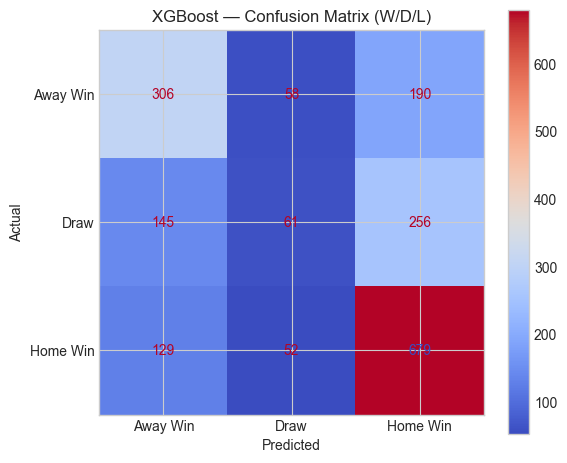


Top 15 XGBoost feature importances:
                   feature  importance
0   num__HomeShotsOnTarget    0.198958
1   num__AwayShotsOnTarget    0.182368
6     num__HomeYellowCards    0.080601
8           num__MatchYear    0.075047
2         num__HomeCorners    0.071222
3         num__AwayCorners    0.070129
7     num__AwayYellowCards    0.066238
5           num__AwayFouls    0.064924
10           num__MatchDoW    0.063736
4           num__HomeFouls    0.063514
9          num__MatchMonth    0.063263


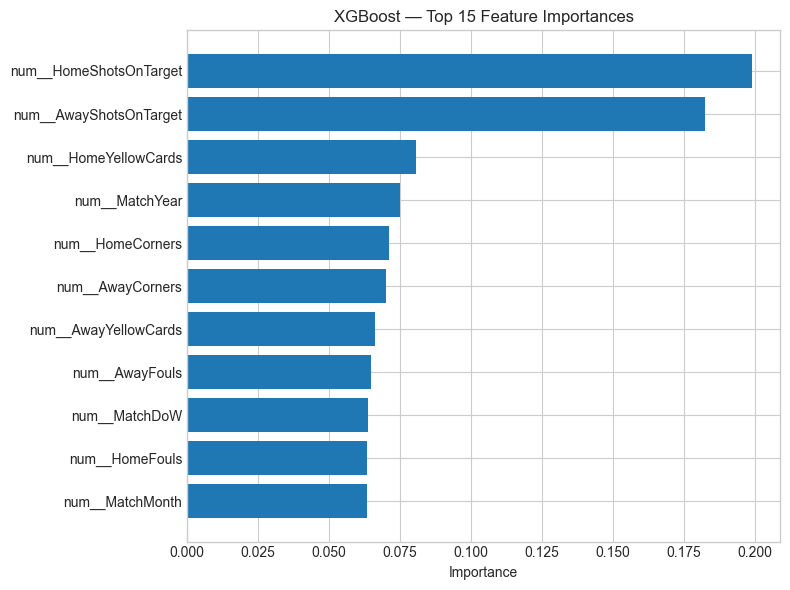

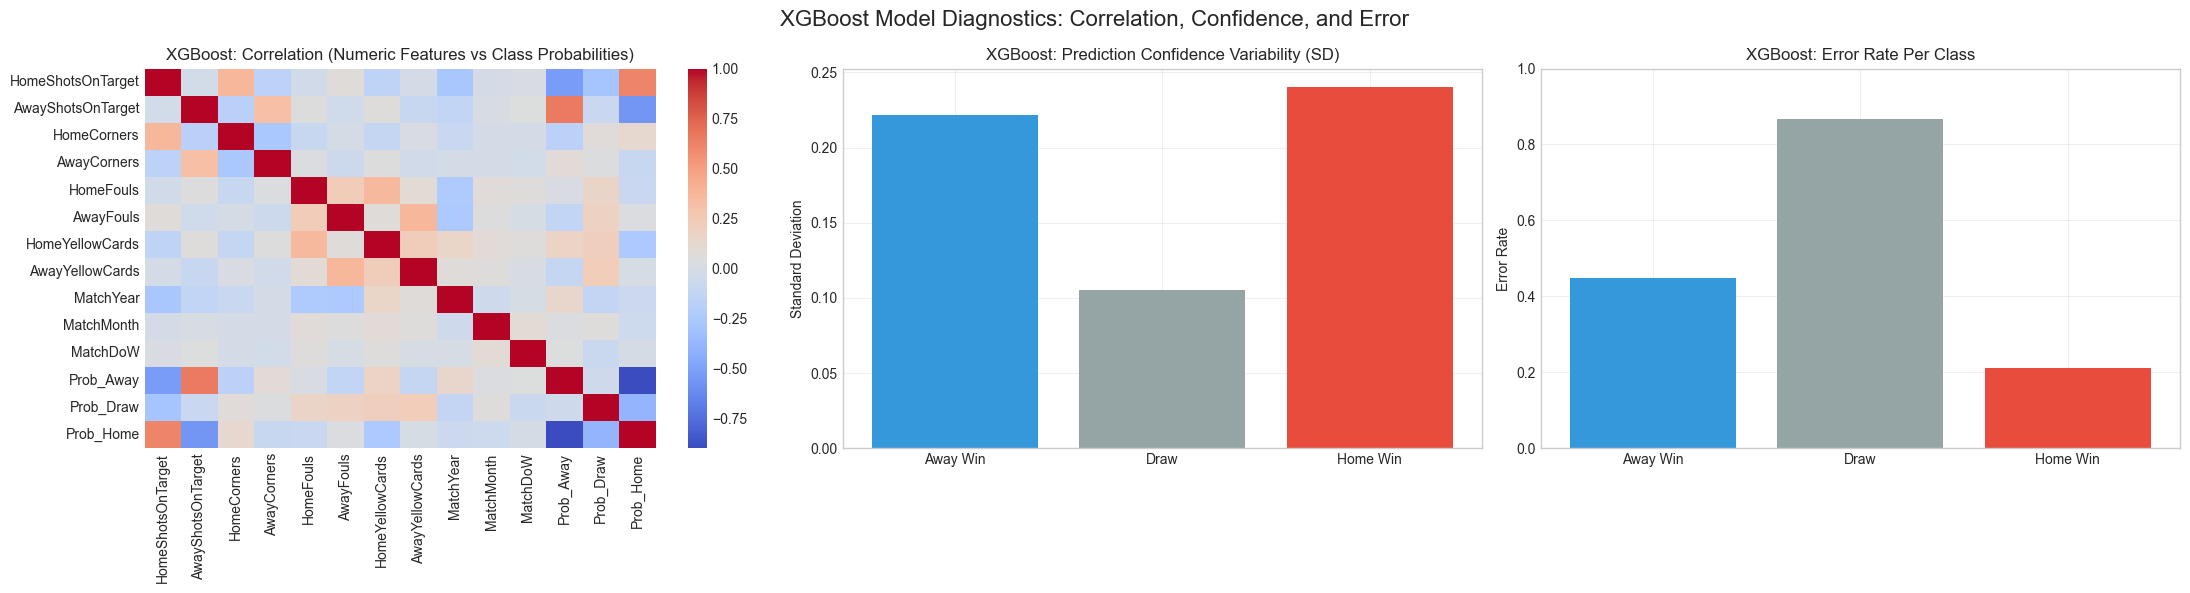

In [44]:
# XGBoost model for Match Result (W/D/L)

xgb_clf = XGBClassifier(
    objective="multi:softprob",  
    num_class=3,                 
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    reg_alpha=0.0,
    tree_method="hist",          
    eval_metric="mlogloss",      
    random_state=42
)

xgb_pipeline = Pipeline(steps=[
    ("prep", preprocessor),
    ("clf",  xgb_clf)
])

# Train
xgb_pipeline.fit(eplLogDatatrain, eplMatchResulttrain)

# Predictions
y_pred_xgb  = xgb_pipeline.predict(eplLogDatatest)
y_proba_xgb = xgb_pipeline.predict_proba(eplLogDatatest)

# Evaluation
acc_xgb      = accuracy_score(eplMatchResulttest, y_pred_xgb)
bal_acc_xgb  = balanced_accuracy_score(eplMatchResulttest, y_pred_xgb)
f1_macro_xgb = f1_score(eplMatchResulttest, y_pred_xgb, average="macro")

print("\n=== XGBoost — Match Result (W/D/L) ===")
print(f"Accuracy:           {acc_xgb*100:.2f}%")
print(f"Balanced Accuracy:  {bal_acc_xgb*100:.2f}%")
print(f"Macro F1-score:     {f1_macro_xgb:.3f}\n")

print("Classification Report (XGBoost):")
print(classification_report(
    eplMatchResulttest,
    y_pred_xgb,
    target_names=["Away Win (0)", "Draw (1)", "Home Win (2)"]
))

# Confusion Matrix
cm_xgb = confusion_matrix(eplMatchResulttest, y_pred_xgb)
disp_xgb = ConfusionMatrixDisplay(
    confusion_matrix=cm_xgb,
    display_labels=["Away Win", "Draw", "Home Win"]
)

fig, ax = plt.subplots(figsize=(6,5))
disp_xgb.plot(cmap="coolwarm", values_format="d", ax=ax)
plt.title("XGBoost — Confusion Matrix (W/D/L)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Feature Importance 
# Get the fitted preprocessor and classifier back from the pipeline
prep_fitted = xgb_pipeline.named_steps["prep"]
xgb_fitted  = xgb_pipeline.named_steps["clf"]

# Names of transformed features
feature_names = prep_fitted.get_feature_names_out()

importances = xgb_fitted.feature_importances_

feat_imp = (
    pd.DataFrame({"feature": feature_names, "importance": importances})
    .sort_values("importance", ascending=False)
    .head(15)
)

print("\nTop 15 XGBoost feature importances:")
print(feat_imp)

plt.figure(figsize=(8,6))
plt.barh(feat_imp["feature"], feat_imp["importance"])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("XGBoost — Top 15 Feature Importances")
plt.tight_layout()
plt.show()


# For convenience, align names with your template
y_test   = eplMatchResulttest
y_pred   = y_pred_xgb
y_proba  = y_proba_xgb
X_test   = eplLogDatatest   # full test dataframe with cat + numeric

# Error rate per class 
errors = []
for cls in [0, 1, 2]:
    cls_idx = (y_test == cls)
    if cls_idx.sum() > 0:
        cls_error = 1 - accuracy_score(y_test[cls_idx], y_pred[cls_idx])
    else:
        cls_error = 0
    errors.append(cls_error)

# Standard deviation of predicted probabilities 
sd_probs = y_proba.std(axis=0)

# Correlation matrix (NUMERIC FEATURES ONLY) 

# Extract only numeric columns from X_test
numeric_X = X_test[numeric_cols].reset_index(drop=True)

# Predicted probabilities
proba_df = pd.DataFrame(
    y_proba,
    columns=["Prob_Away", "Prob_Draw", "Prob_Home"]
)

# Combine numeric features + probabilities
corr_df = pd.concat([numeric_X, proba_df], axis=1)

# Compute correlation
corr_matrix = corr_df.corr()

#  Combined Figure 
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

#  Plot A: Correlation heatmap 
sns.heatmap(
    corr_matrix,
    ax=axes[0],
    cmap="coolwarm",
    annot=False
)
axes[0].set_title("XGBoost: Correlation (Numeric Features vs Class Probabilities)")

#  Plot B: Standard deviation of predicted probabilities 
axes[1].bar(
    ["Away Win","Draw","Home Win"],
    sd_probs,
    color=["#3498db", "#95a5a6", "#e74c3c"]
)
axes[1].set_title("XGBoost: Prediction Confidence Variability (SD)")
axes[1].set_ylabel("Standard Deviation")
axes[1].grid(alpha=0.3)

#  Plot C: Error rate per class 
axes[2].bar(
    ["Away Win","Draw","Home Win"],
    errors,
    color=["#3498db", "#95a5a6", "#e74c3c"]
)
axes[2].set_title("XGBoost: Error Rate Per Class")
axes[2].set_ylabel("Error Rate")
axes[2].set_ylim(0, 1)
axes[2].grid(alpha=0.3)

plt.suptitle("XGBoost Model Diagnostics: Correlation, Confidence, and Error", fontsize=16)
plt.tight_layout()
plt.show()

##### XGBoost more advance

##### Build TEAM-LEVEL LONG TABLE (one row per team per match)

In [45]:

# SeasonStartYear
if "SeasonStartYear" not in eplData.columns:
    if "Season" in eplData.columns:
        # Extract first 4 characters of Season string as year
        eplData["SeasonStartYear"] = (
            eplData["Season"].astype(str).str.slice(0, 4).astype(int)
        )
    else:
        # fallback: use MatchYear from your earlier code
        eplData["SeasonStartYear"] = eplData["MatchYear"]

# Goal columns
if "FullTimeHomeGoals" in eplData.columns and "FullTimeAwayGoals" in eplData.columns:
    home_goals_col = "FullTimeHomeGoals"
    away_goals_col = "FullTimeAwayGoals"
else:
    raise ValueError(
        "Need goal columns. Expected either "
        "['FullTimeHomeGoals','FullTimeAwayGoals'] in eplData."
    )

# Home-view
home_long = pd.DataFrame({
    "SeasonStartYear": eplData["SeasonStartYear"],
    "MatchDate":       eplData["MatchDate"],
    "Team":            eplData["HomeTeam"],
    "Opponent":        eplData["AwayTeam"],
    "IsHome":          1,
    "GoalsFor":        eplData[home_goals_col],
    "GoalsAgainst":    eplData[away_goals_col],
})

# Away-view
away_long = pd.DataFrame({
    "SeasonStartYear": eplData["SeasonStartYear"],
    "MatchDate":       eplData["MatchDate"],
    "Team":            eplData["AwayTeam"],
    "Opponent":        eplData["HomeTeam"],
    "IsHome":          0,
    "GoalsFor":        eplData[away_goals_col],
    "GoalsAgainst":    eplData[home_goals_col],
})

team_long = pd.concat([home_long, away_long], ignore_index=True)

# Points from home-based MatchResult (2=home win, 1=draw, 0=away win)
result = eplData["MatchResult"].values

home_points = np.select(
    [result == 2, result == 1, result == 0],
    [3, 1, 0],
    default=0
)
away_points = np.select(
    [result == 0, result == 1, result == 2],
    [3, 1, 0],
    default=0
)

team_long["Points"] = np.concatenate([home_points, away_points])

# TeamResult from that team's perspective (2=win, 1=draw, 0=loss)
team_long["TeamResult"] = np.where(
    team_long["Points"] == 3, 2,
    np.where(team_long["Points"] == 1, 1, 0)
)

team_long = team_long.sort_values(
    ["Team", "SeasonStartYear", "MatchDate"]
).reset_index(drop=True)

print("Long-format team data sample:")
display(team_long.head(10)
    .style.set_table_styles([
        {"selector": "th", "props": [("background-color", "#2c3e50"), ("color", "white"), ("font-weight", "bold")]}
    ]))

Long-format team data sample:


,SeasonStartYear,MatchDate,Team,Opponent,IsHome,GoalsFor,GoalsAgainst,Points,TeamResult
0,2000,2000-08-19 00:00:00,Arsenal,Sunderland,0,0,1,0,0
1,2000,2000-08-21 00:00:00,Arsenal,Liverpool,1,2,0,3,2
2,2000,2000-08-26 00:00:00,Arsenal,Charlton,1,5,3,3,2
3,2000,2000-09-06 00:00:00,Arsenal,Chelsea,0,2,2,1,1
4,2000,2000-09-09 00:00:00,Arsenal,Bradford,0,1,1,1,1
5,2000,2000-09-16 00:00:00,Arsenal,Coventry,1,2,1,3,2
6,2000,2000-09-23 00:00:00,Arsenal,Ipswich,0,1,1,1,1
7,2000,2000-10-01 00:00:00,Arsenal,Man United,1,1,0,3,2
8,2000,2000-10-14 00:00:00,Arsenal,Aston Villa,1,1,0,3,2
9,2000,2000-10-21 00:00:00,Arsenal,West Ham,0,2,1,3,2



##### Aggregate per team-season (agg_df) + LEAGUE POSITION


In [46]:
# Compute league position per team per season
agg_df = (
    team_long
    .groupby(["Team", "SeasonStartYear"], as_index=False)
    .agg(
        Matches=("MatchDate", "count"),
        Points=("Points", "sum"),
        GoalsFor=("GoalsFor", "sum"),
        GoalsAgainst=("GoalsAgainst", "sum")
    )
)

agg_df["GoalDiff"] = agg_df["GoalsFor"] - agg_df["GoalsAgainst"]

agg_df = agg_df.sort_values(
    ["SeasonStartYear", "Points", "GoalDiff", "GoalsFor"],
    ascending=[True, False, False, False]
)
agg_df["LeaguePos"] = (
    agg_df
    .groupby("SeasonStartYear")
    .cumcount() + 1
)

# Merge league position into team_long
team_long = team_long.merge(
    agg_df[["Team", "SeasonStartYear", "LeaguePos"]],
    on=["Team", "SeasonStartYear"],
    how="left"
)
# Display sample with LeaguePos
print("Team long-format data with League Position sample:")
display(team_long.head(10)
    .style.set_table_styles([
        {"selector": "th", "props": [("background-color", "#2c3e50"), ("color", "white"), ("font-weight", "bold")]}
    ]))

Team long-format data with League Position sample:


,SeasonStartYear,MatchDate,Team,Opponent,IsHome,GoalsFor,GoalsAgainst,Points,TeamResult,LeaguePos
0,2000,2000-08-19 00:00:00,Arsenal,Sunderland,0,0,1,0,0,2
1,2000,2000-08-21 00:00:00,Arsenal,Liverpool,1,2,0,3,2,2
2,2000,2000-08-26 00:00:00,Arsenal,Charlton,1,5,3,3,2,2
3,2000,2000-09-06 00:00:00,Arsenal,Chelsea,0,2,2,1,1,2
4,2000,2000-09-09 00:00:00,Arsenal,Bradford,0,1,1,1,1,2
5,2000,2000-09-16 00:00:00,Arsenal,Coventry,1,2,1,3,2,2
6,2000,2000-09-23 00:00:00,Arsenal,Ipswich,0,1,1,1,1,2
7,2000,2000-10-01 00:00:00,Arsenal,Man United,1,1,0,3,2,2
8,2000,2000-10-14 00:00:00,Arsenal,Aston Villa,1,1,0,3,2,2
9,2000,2000-10-21 00:00:00,Arsenal,West Ham,0,2,1,3,2,2



##### STEP 3: Add LAST-5 form stats (GF, GA, Points) per team, per season


In [47]:
# Compute last 5 matches form metrics
def add_last5_form(group):
    group = group.sort_values("MatchDate")
    group["GF_Last5"] = (
        group["GoalsFor"].shift().rolling(5, min_periods=1).sum()
    )
    group["GA_Last5"] = (
        group["GoalsAgainst"].shift().rolling(5, min_periods=1).sum()
    )
    group["Pts_Last5"] = (
        group["Points"].shift().rolling(5, min_periods=1).sum()
    )
    return group
# Apply to each team-season group
team_long = (
    team_long
    .groupby(["Team", "SeasonStartYear"], group_keys=False)
    .apply(add_last5_form)
)

team_long = team_long.dropna(subset=["GF_Last5", "GA_Last5", "Pts_Last5"])

# Display sample with last 5 matches form metrics
print("Team long-format data with last 5 matches form sample:")
display(team_long.head(10)
    .style.set_table_styles([
        {"selector": "th", "props": [("background-color", "#2c3e50"), ("color", "white"), ("font-weight", "bold")]}
    ]))

Team long-format data with last 5 matches form sample:


,SeasonStartYear,MatchDate,Team,Opponent,IsHome,GoalsFor,GoalsAgainst,Points,TeamResult,LeaguePos,GF_Last5,GA_Last5,Pts_Last5
1,2000,2000-08-21 00:00:00,Arsenal,Liverpool,1,2,0,3,2,2,0.000000,1.000000,0.000000
2,2000,2000-08-26 00:00:00,Arsenal,Charlton,1,5,3,3,2,2,2.000000,1.000000,3.000000
3,2000,2000-09-06 00:00:00,Arsenal,Chelsea,0,2,2,1,1,2,7.000000,4.000000,6.000000
4,2000,2000-09-09 00:00:00,Arsenal,Bradford,0,1,1,1,1,2,9.000000,6.000000,7.000000
5,2000,2000-09-16 00:00:00,Arsenal,Coventry,1,2,1,3,2,2,10.000000,7.000000,8.000000
6,2000,2000-09-23 00:00:00,Arsenal,Ipswich,0,1,1,1,1,2,12.000000,7.000000,11.000000
7,2000,2000-10-01 00:00:00,Arsenal,Man United,1,1,0,3,2,2,11.000000,8.000000,9.000000
8,2000,2000-10-14 00:00:00,Arsenal,Aston Villa,1,1,0,3,2,2,7.000000,5.000000,9.000000
9,2000,2000-10-21 00:00:00,Arsenal,West Ham,0,2,1,3,2,2,6.000000,3.000000,11.000000
10,2000,2000-10-28 00:00:00,Arsenal,Man City,1,5,0,3,2,2,7.000000,3.000000,13.000000


##### STEP 4: Select TWO LONG-SPAN TEAMS (2000–2025)

In [48]:
# Select two teams with long-span data from 2000 to 2025
mask_2000_2025 = (
    (agg_df["SeasonStartYear"] >= 2000) &
    (agg_df["SeasonStartYear"] <= 2025)
)
agg_2000_2025 = agg_df[mask_2000_2025].copy()

# Determine teams with full coverage from 2000 to 2025
team_span = (
    agg_2000_2025
    .groupby("Team")["SeasonStartYear"]
    .agg(["min", "max"])
)

teams_full_span = team_span[
    (team_span["min"] <= 2000) & (team_span["max"] >= 2025)
].index.tolist()

print("Teams with coverage from 2000 to 2025:", teams_full_span)

# Relax condition if too strict
if len(teams_full_span) < 2:
    max_year = agg_2000_2025["SeasonStartYear"].max()
    teams_full_span = team_span[
        (team_span["min"] <= 2001) & (team_span["max"] >= max_year)
    ].index.tolist()
    print("Relaxed selection, teams with long-span coverage:", teams_full_span)

selected_teams = sorted(teams_full_span)[:2]
if len(selected_teams) < 2:
    raise ValueError("Not enough teams with long-span data between 2000 and 2025.")

team_home = selected_teams[0]
team_away = selected_teams[1]
print(f"\n📌 Two-team model: {team_home} vs {team_away}")



Teams with coverage from 2000 to 2025: []
Relaxed selection, teams with long-span coverage: ['Arsenal', 'Aston Villa', 'Chelsea', 'Everton', 'Fulham', 'Ipswich', 'Leicester', 'Liverpool', 'Man City', 'Man United', 'Newcastle', 'Southampton', 'Tottenham', 'West Ham']

📌 Two-team model: Arsenal vs Aston Villa


##### STEP 5: Build MATCH-LEVEL subset only for these two teams

In [49]:

# Limit to matches where both sides are among selected teams
two_team_matches = eplData[
    eplData["HomeTeam"].isin(selected_teams) &
    eplData["AwayTeam"].isin(selected_teams)
].copy()

# Restrict to 2000–2025 seasons
two_team_matches = two_team_matches[
    (two_team_matches["SeasonStartYear"] >= 2000) &
    (two_team_matches["SeasonStartYear"] <= 2025)
].copy()

print(f"\nTotal matches between {team_home} and {team_away}: {len(two_team_matches)}")


# Team_long for merging
merge_cols = [
    "Team", "SeasonStartYear", "MatchDate",
    "GF_Last5", "GA_Last5", "Pts_Last5", "LeaguePos"
]

home_form = team_long[merge_cols].rename(columns={
    "Team": "HomeTeam",
    "GF_Last5": "Home_GF_Last5",
    "GA_Last5": "Home_GA_Last5",
    "Pts_Last5": "Home_Pts_Last5",
    "LeaguePos": "Home_LeaguePos"
})

away_form = team_long[merge_cols].rename(columns={
    "Team": "AwayTeam",
    "GF_Last5": "Away_GF_Last5",
    "GA_Last5": "Away_GA_Last5",
    "Pts_Last5": "Away_Pts_Last5",
    "LeaguePos": "Away_LeaguePos"
})

# Merge for home team form
two_team_matches = two_team_matches.merge(
    home_form,
    on=["HomeTeam", "SeasonStartYear", "MatchDate"],
    how="left"
)

# Merge for away team form
two_team_matches = two_team_matches.merge(
    away_form,
    on=["AwayTeam", "SeasonStartYear", "MatchDate"],
    how="left"
)

# Drop rows with missing features or target
feature_cols = [
    "Home_GF_Last5", "Home_GA_Last5", "Home_Pts_Last5",
    "Away_GF_Last5", "Away_GA_Last5", "Away_Pts_Last5",
    "Home_LeaguePos", "Away_LeaguePos"
]

model_df = two_team_matches.dropna(subset=feature_cols + ["MatchResult"]).copy()

# Sort by date for realistic time split
model_df = model_df.sort_values("MatchDate").reset_index(drop=True)

X = model_df[feature_cols].values
y = model_df["MatchResult"].astype(int).values   # 2=home win,1=draw,0=away win

print(f"\nUsable two-team matches for modelling: {len(model_df)}")


split_idx = int(len(model_df) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

print(f"Train size: {len(y_train)}, Test size: {len(y_test)}")

# Preprocessor 

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor_two = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, list(range(len(feature_cols)))),
    ]
)
# XGBoost Classifier for two-team model
xgb_clf_two = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    n_estimators=500,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.9,
    colsample_bytree=0.9,
    reg_lambda=1.0,
    reg_alpha=0.1,
    tree_method="hist",
    eval_metric="mlogloss",
    random_state=42
)

xgb_two_pipeline = Pipeline(steps=[
    ("prep", preprocessor_two),
    ("clf",  xgb_clf_two)
])

# Train two-team XGBoost model
xgb_two_pipeline.fit(X_train, y_train)

# Predictions
y_pred = xgb_two_pipeline.predict(X_test)
y_proba = xgb_two_pipeline.predict_proba(X_test)

# Evaluation
acc      = accuracy_score(y_test, y_pred)
bal_acc  = balanced_accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")

print("\n=== Advanced XGBoost — Two-Team Match Result (W/D/L) ===")
print(f"Accuracy:           {acc*100:.2f}%")
print(f"Balanced Accuracy:  {bal_acc*100:.2f}%")
print(f"Macro F1-score:     {f1_macro:.3f}\n")

# Classification Report
print("Classification Report (Advanced XGBoost, Two-Team):")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Away Win (0)", "Draw (1)", "Home Win (2)"]
))



Total matches between Arsenal and Aston Villa: 44

Usable two-team matches for modelling: 42
Train size: 33, Test size: 9

=== Advanced XGBoost — Two-Team Match Result (W/D/L) ===
Accuracy:           55.56%
Balanced Accuracy:  66.67%
Macro F1-score:     0.556

Classification Report (Advanced XGBoost, Two-Team):
              precision    recall  f1-score   support

Away Win (0)       0.50      0.50      0.50         4
    Draw (1)       0.33      1.00      0.50         1
Home Win (2)       1.00      0.50      0.67         4

    accuracy                           0.56         9
   macro avg       0.61      0.67      0.56         9
weighted avg       0.70      0.56      0.57         9



Visulize

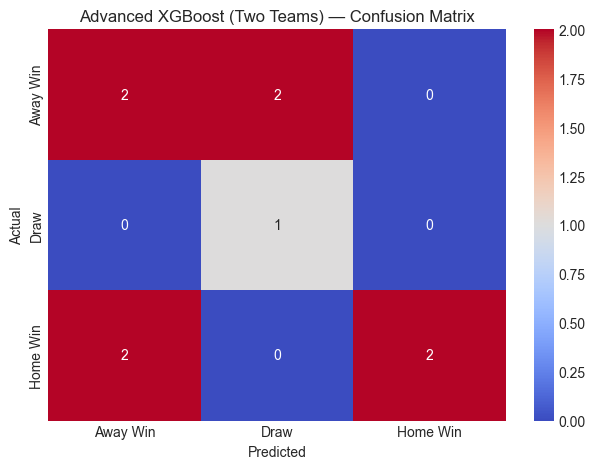

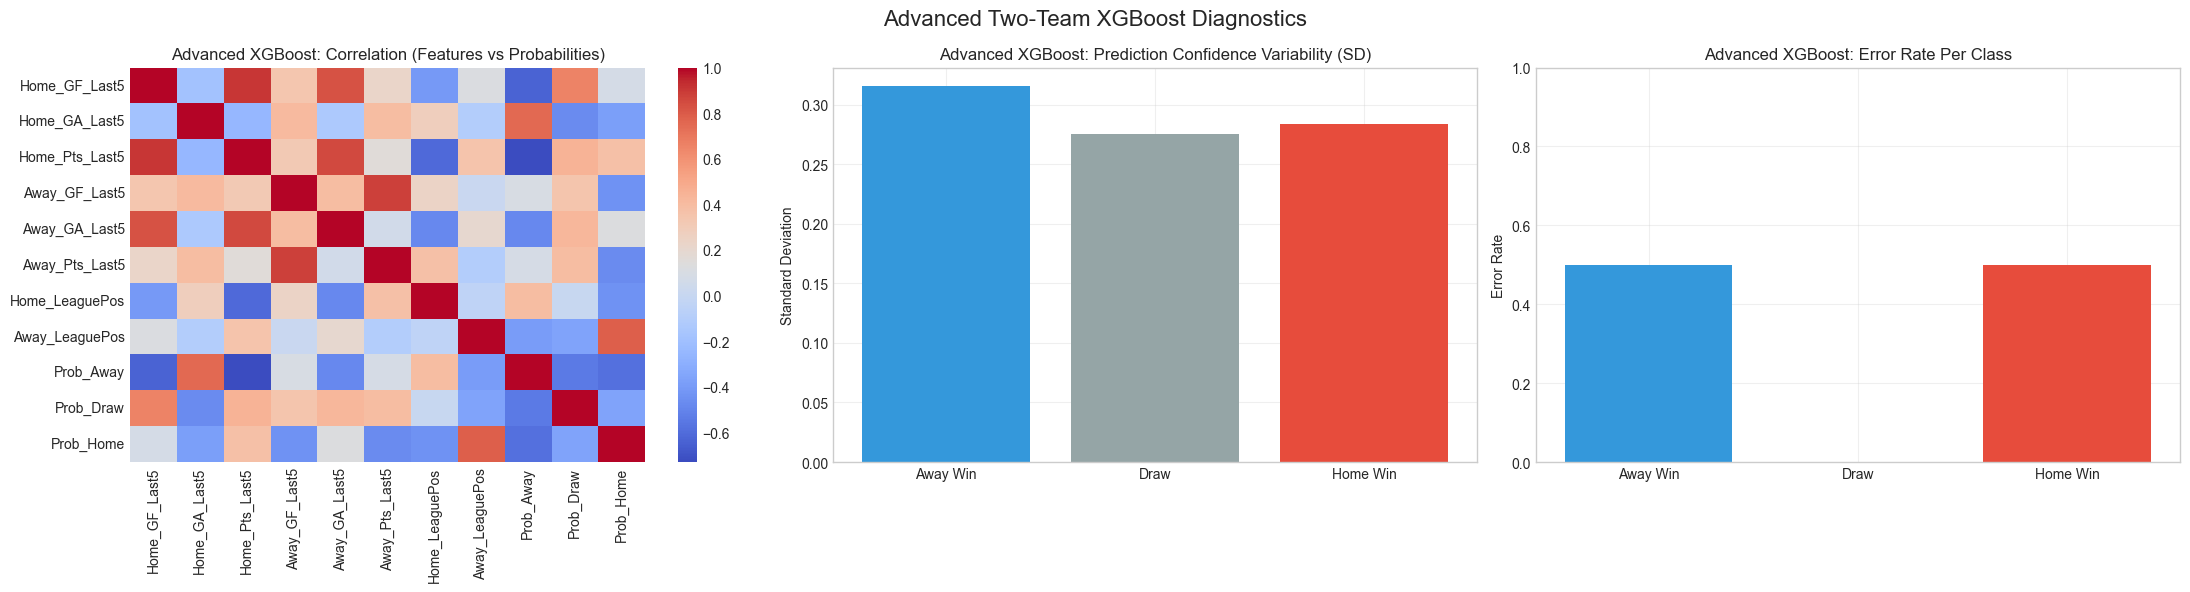

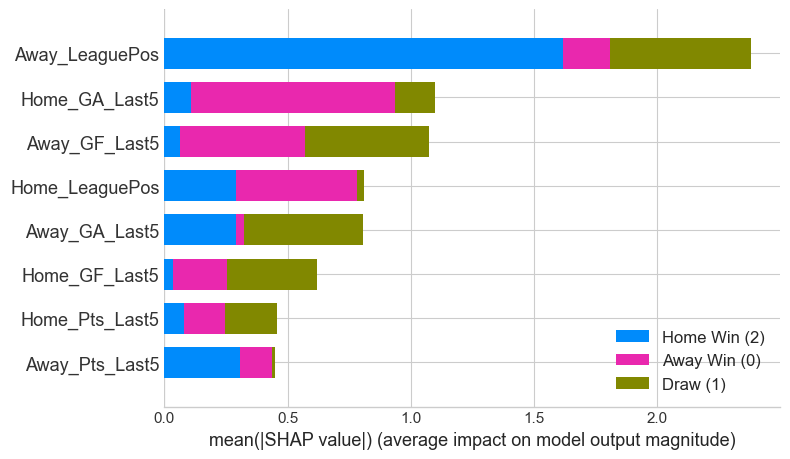

In [50]:
# Confusion Matrix Plot
cm = confusion_matrix(y_test, y_pred)
disp = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="coolwarm",
    xticklabels=["Away Win","Draw","Home Win"],
    yticklabels=["Away Win","Draw","Home Win"]
)
plt.title("Advanced XGBoost (Two Teams) — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


# Error rate per class
errors = []
for cls in [0, 1, 2]:
    cls_idx = (y_test == cls)
    if cls_idx.sum() > 0:
        cls_error = 1 - accuracy_score(y_test[cls_idx], y_pred[cls_idx])
    else:
        cls_error = 0
    errors.append(cls_error)

# Standard deviation of predicted probabilities
sd_probs = y_proba.std(axis=0)

# Correlation matrix between numeric features and class probs
numeric_X_test = pd.DataFrame(X_test, columns=feature_cols).reset_index(drop=True)
proba_df = pd.DataFrame(
    y_proba,
    columns=["Prob_Away", "Prob_Draw", "Prob_Home"]
)
corr_df = pd.concat([numeric_X_test, proba_df], axis=1)
corr_matrix = corr_df.corr()

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# A: Correlation heatmap
sns.heatmap(
    corr_matrix,
    ax=axes[0],
    cmap="coolwarm",
    annot=False
)
axes[0].set_title("Advanced XGBoost: Correlation (Features vs Probabilities)")

# B: SD of predicted probabilities
axes[1].bar(
    ["Away Win", "Draw", "Home Win"],
    sd_probs,
    color=["#3498db", "#95a5a6", "#e74c3c"]
)
axes[1].set_title("Advanced XGBoost: Prediction Confidence Variability (SD)")
axes[1].set_ylabel("Standard Deviation")
axes[1].grid(alpha=0.3)

# C: Error rate per class
axes[2].bar(
    ["Away Win", "Draw", "Home Win"],
    errors,
    color=["#3498db", "#95a5a6", "#e74c3c"]
)
axes[2].set_title("Advanced XGBoost: Error Rate Per Class")
axes[2].set_ylabel("Error Rate")
axes[2].set_ylim(0, 1)
axes[2].grid(alpha=0.3)

plt.suptitle("Advanced Two-Team XGBoost Diagnostics", fontsize=16)
plt.tight_layout()
plt.show()

# SHAP Summary Plot for Two-Team XGBoost Model

prep_fitted = xgb_two_pipeline.named_steps["prep"]
xgb_model   = xgb_two_pipeline.named_steps["clf"]

# Transform data using the fitted preprocessor
X_train_trans = prep_fitted.transform(X_train)
X_test_trans  = prep_fitted.transform(X_test)

# Convert to dense if needed
if not isinstance(X_test_trans, np.ndarray):
    X_test_dense = X_test_trans.toarray()
else:
    X_test_dense = X_test_trans

feature_names_trans = feature_cols  # 8 features we actually modelled

# SHAP values
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_dense)
class_names = ["Away Win (0)", "Draw (1)", "Home Win (2)"]

shap.summary_plot(
    shap_values,
    X_test_dense,
    feature_names=feature_names_trans,
    class_names=class_names,
    plot_type="bar",
)


##### Lasso and Ridge 

##### PREPARE TEAM-MATCH LEVEL DATA 

In [51]:
# Transform eplData to team-match level format
eplData["MatchDate"] = pd.to_datetime(eplData["MatchDate"])
eplData["SeasonStartYear"] = eplData["Season"].str[:4].astype(int)
eplData["MatchID"] = np.arange(len(eplData))

# Home-view DataFrame
home_eplData = pd.DataFrame({
    "Season": eplData["Season"],
    "SeasonStartYear": eplData["SeasonStartYear"],
    "Team": eplData["HomeTeam"],
    "GoalsFor": eplData["FullTimeHomeGoals"],
    "GoalsAgainst": eplData["FullTimeAwayGoals"],
    "Shots": eplData["HomeShots"],
    "ShotsOnTarget": eplData["HomeShotsOnTarget"],
    "Corners": eplData["HomeCorners"],
    "Fouls": eplData["HomeFouls"],
    "YellowCards": eplData["HomeYellowCards"],
    "RedCards": eplData["HomeRedCards"],
    "Points": np.where(eplData["FullTimeResult"] == "H", 3,
                np.where(eplData["FullTimeResult"] == "D", 1, 0)),
})

# Away-view DataFrame
away_eplData = pd.DataFrame({
    "Season": eplData["Season"],
    "SeasonStartYear": eplData["SeasonStartYear"],
    "Team": eplData["AwayTeam"],
    "GoalsFor": eplData["FullTimeAwayGoals"],
    "GoalsAgainst": eplData["FullTimeHomeGoals"],
    "Shots": eplData["AwayShots"],
    "ShotsOnTarget": eplData["AwayShotsOnTarget"],
    "Corners": eplData["AwayCorners"],
    "Fouls": eplData["AwayFouls"],
    "YellowCards": eplData["AwayYellowCards"],
    "RedCards": eplData["AwayRedCards"],
    "Points": np.where(eplData["FullTimeResult"] == "A", 3,
                np.where(eplData["FullTimeResult"] == "D", 1, 0)),
})

# Combine home and away views
team_match_eplData = pd.concat([home_eplData, away_eplData], ignore_index=True)

print("Team-match level EPL data sample:")
display(team_match_eplData.head(10)
    .style.set_table_styles([
        {"selector": "th", "props": [("background-color", "#2c3e50"), ("color", "white"), ("font-weight", "bold")]}
    ]))


Team-match level EPL data sample:


,Season,SeasonStartYear,Team,GoalsFor,GoalsAgainst,Shots,ShotsOnTarget,Corners,Fouls,YellowCards,RedCards,Points
0,2000/01,2000,Charlton,4,0,17,14,6,13,1,0,3
1,2000/01,2000,Chelsea,4,2,17,10,7,19,1,0,3
2,2000/01,2000,Coventry,1,3,6,3,8,15,5,1,0
3,2000/01,2000,Derby,2,2,6,4,5,11,1,0,1
4,2000/01,2000,Leeds,2,0,17,8,6,21,1,0,3
5,2000/01,2000,Leicester,0,0,5,4,5,12,2,0,1
6,2000/01,2000,Liverpool,1,0,16,10,6,8,1,0,3
7,2000/01,2000,Sunderland,1,0,8,2,2,10,3,0,3
8,2000/01,2000,Tottenham,3,1,20,6,3,14,0,0,3
9,2000/01,2000,Man United,2,0,19,9,7,7,0,0,3


##### SEASON-LEVEL AGGREGATION

In [52]:
# Aggregate season stats per team
agg_eplData = (
    team_match_eplData
    .groupby(["Season", "SeasonStartYear", "Team"], as_index=False)
    .agg({
        "GoalsFor": "sum",
        "GoalsAgainst": "sum",
        "Shots": "sum",
        "ShotsOnTarget": "sum",
        "Corners": "sum",
        "Fouls": "sum",
        "YellowCards": "sum",
        "RedCards": "sum",
        "Points": "sum",
    })
)

# Count matches played per team per season
match_counts = (
    team_match_eplData
    .groupby(["Season", "Team"])
    .size()
    .reset_index(name="Matches")
)

agg_eplData = agg_eplData.merge(match_counts, on=["Season", "Team"], how="left")

# Derived season stats
agg_eplData["GoalDifference"]       = agg_eplData["GoalsFor"] - agg_eplData["GoalsAgainst"]
agg_eplData["PointsPerGame"]        = agg_eplData["Points"] / agg_eplData["Matches"]
agg_eplData["GoalsForPerGame"]      = agg_eplData["GoalsFor"] / agg_eplData["Matches"]
agg_eplData["GoalsAgainstPerGame"]  = agg_eplData["GoalsAgainst"] / agg_eplData["Matches"]
agg_eplData["ShotsPerGame"]         = agg_eplData["Shots"] / agg_eplData["Matches"]
agg_eplData["ShotsOnTargetPerGame"] = agg_eplData["ShotsOnTarget"] / agg_eplData["Matches"]

# Drop any rows
agg_eplData = agg_eplData.dropna(subset=["PointsPerGame"]).reset_index(drop=True)

# COMPARE 2 TEAMS (2000–2025 WINDOW)
mask_2000_2025 = (agg_eplData["SeasonStartYear"] >= 2000) & (agg_eplData["SeasonStartYear"] <= 2025)
agg_2000_2025 = agg_eplData[mask_2000_2025].copy()

team_span = (
    agg_2000_2025
    .groupby("Team")["SeasonStartYear"]
    .agg(["min", "max"])
)

teams_full_span = team_span[
    (team_span["min"] <= 2000) & (team_span["max"] >= 2025)
].index.tolist()

print("Teams with coverage from 2000 to 2025:", teams_full_span)

# Relax condition if too strict
if len(teams_full_span) < 2:
    max_year = agg_2000_2025["SeasonStartYear"].max()
    teams_full_span = team_span[
        (team_span["min"] <= 2001) & (team_span["max"] >= max_year)
    ].index.tolist()
    print("Relaxed selection, teams with long-span coverage:", teams_full_span)

selected_teams = sorted(teams_full_span)[:2]
if len(selected_teams) < 2:
    raise ValueError("Not enough teams with long-span data between 2000 and 2025.")
# Drop rows 
team_home = selected_teams[0]
team_away = selected_teams[1]

print(f"Comparing teams from 2000–2025: {team_home} vs {team_away}")
if "team_home" not in globals() or "team_away" not in globals():
    raise RuntimeError("Run the XGBoost two-team selection cell first to define team_home and team_away.")

selected_teams = [team_home, team_away]
print(f"Comparing teams from 2000–2025 (same as XGBoost): {team_home} vs {team_away}")

#  Build eplData_two FROM agg_2000_2025
eplData_two = agg_2000_2025[agg_2000_2025["Team"].isin(selected_teams)].copy()
eplData_two = eplData_two.sort_values(["SeasonStartYear", "Team"])
print(eplData_two.columns)


Teams with coverage from 2000 to 2025: []
Relaxed selection, teams with long-span coverage: ['Arsenal', 'Aston Villa', 'Chelsea', 'Everton', 'Fulham', 'Ipswich', 'Leicester', 'Liverpool', 'Man City', 'Man United', 'Newcastle', 'Southampton', 'Tottenham', 'West Ham']
Comparing teams from 2000–2025: Arsenal vs Aston Villa
Comparing teams from 2000–2025 (same as XGBoost): Arsenal vs Aston Villa
Index(['Season', 'SeasonStartYear', 'Team', 'GoalsFor', 'GoalsAgainst',
       'Shots', 'ShotsOnTarget', 'Corners', 'Fouls', 'YellowCards', 'RedCards',
       'Points', 'Matches', 'GoalDifference', 'PointsPerGame',
       'GoalsForPerGame', 'GoalsAgainstPerGame', 'ShotsPerGame',
       'ShotsOnTargetPerGame'],
      dtype='object')


##### Visualization and Graphs

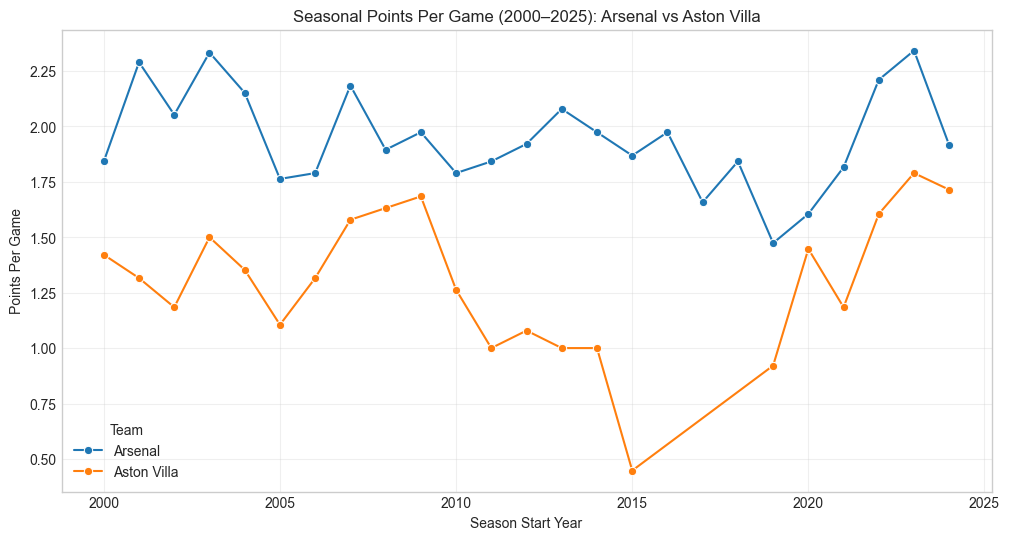

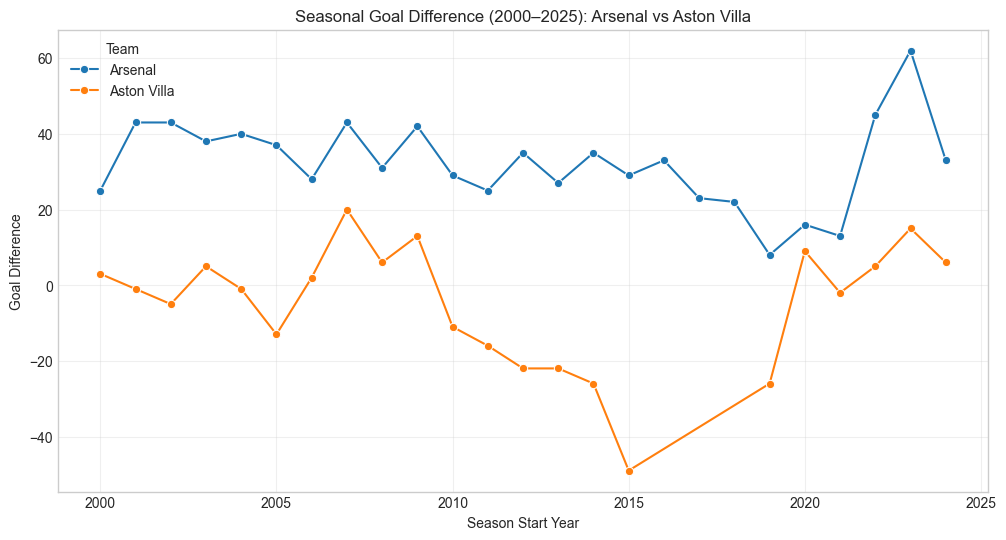

In [53]:

# --------  Points Per Game --------
plt.figure(figsize=(12,6))
sns.lineplot(
    data=eplData_two,
    x="SeasonStartYear",
    y="PointsPerGame",
    hue="Team",
    marker="o"
)
plt.title(f"Seasonal Points Per Game (2000–2025): {team_home} vs {team_away}")
plt.xlabel("Season Start Year")
plt.ylabel("Points Per Game")
plt.grid(True, alpha=0.3)
plt.legend(title="Team")
plt.show()

# --------  Goal Difference --------
plt.figure(figsize=(12,6))
sns.lineplot(
    data=eplData_two,
    x="SeasonStartYear",
    y="GoalDifference",
    hue="Team",
    marker="o"
)
plt.title(f"Seasonal Goal Difference (2000–2025): {team_home} vs {team_away}")
plt.xlabel("Season Start Year")
plt.ylabel("Goal Difference")
plt.grid(True, alpha=0.3)
plt.legend(title="Team")
plt.show()


##### BUILD PREDICTIVE MODELS (RIDGE + LASSO)

In [54]:
# Prepare data for regression models
feature_cols = [
    "SeasonStartYear",
    "GoalsForPerGame",
    "GoalsAgainstPerGame",
    "GoalDifference",
    "ShotsPerGame",
    "ShotsOnTargetPerGame",
    "Corners",
    "Fouls",
    "YellowCards",
    "RedCards"
]

aggEplFeatures = agg_eplData[feature_cols].values
aggPointsPerGame = agg_eplData["PointsPerGame"].values

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    aggEplFeatures, aggPointsPerGame, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Ridge and Lasso Regression
ridge = Ridge(alpha=1.0)
lasso = Lasso(alpha=0.05, max_iter=10000)

# Train models
ridge.fit(X_train_scaled, y_train)
lasso.fit(X_train_scaled, y_train)

# Predictions
ridge_pred = ridge.predict(X_test_scaled)
lasso_pred = lasso.predict(X_test_scaled)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

print("RIDGE -> RMSE:", rmse(y_test, ridge_pred), "R2:", r2_score(y_test, ridge_pred))
print("LASSO -> RMSE:", rmse(y_test, lasso_pred), "R2:", r2_score(y_test, lasso_pred))


RIDGE -> RMSE: 0.11637034657124866 R2: 0.9402405644857217
LASSO -> RMSE: 0.13163007793792397 R2: 0.9235403848141556


##### MODEL COMPARISON TABLE + BAR CHART (RIDGE vs LASSO)


Model Comparison Table (Ridge vs Lasso):


,Metric,Ridge,Lasso
0,RMSE,0.116370,0.131630
1,MAE,0.091923,0.101857
2,R² Score,0.940241,0.923540


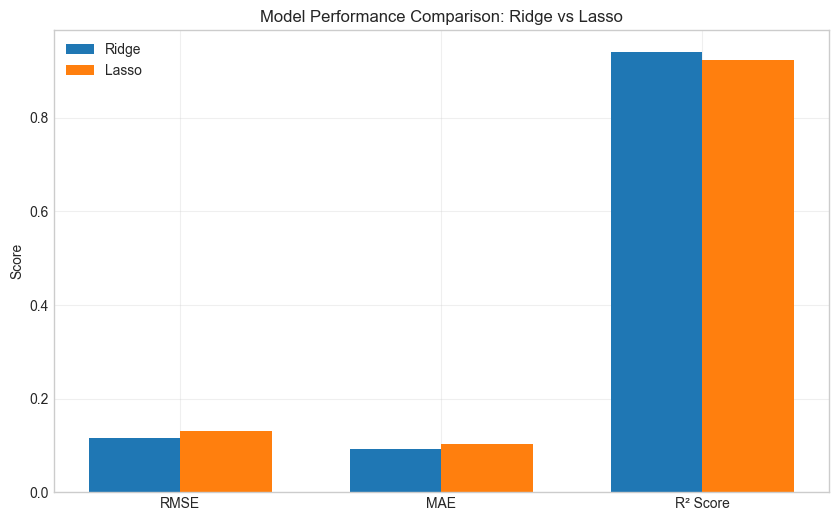

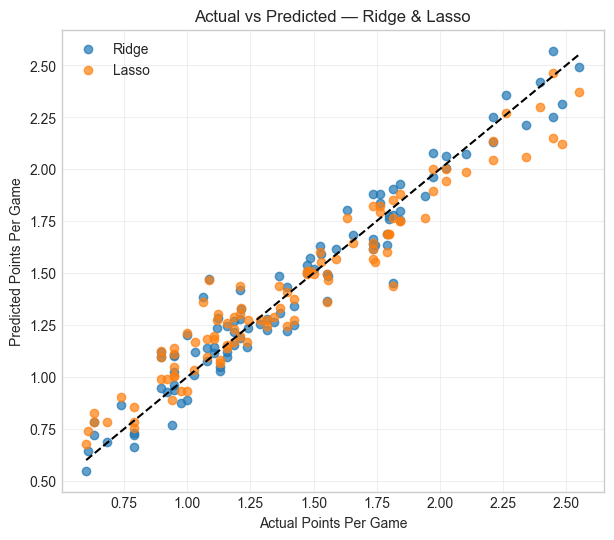

In [55]:
# MODEL COMPARISON TABLE & BAR PLOT
comparison_table = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R² Score"],
    "Ridge": [
        rmse(y_test, ridge_pred),
        mean_absolute_error(y_test, ridge_pred),
        r2_score(y_test, ridge_pred)
    ],
    "Lasso": [
        rmse(y_test, lasso_pred),
        mean_absolute_error(y_test, lasso_pred),
        r2_score(y_test, lasso_pred)
    ]
})

# Display comparison table
print("\nModel Comparison Table (Ridge vs Lasso):")
display(comparison_table)

metrics = comparison_table["Metric"].tolist()
ridge_scores = comparison_table["Ridge"].values
lasso_scores = comparison_table["Lasso"].values

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10,6))
plt.bar(x - width/2, ridge_scores, width, label="Ridge")
plt.bar(x + width/2, lasso_scores, width, label="Lasso")

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.title("Model Performance Comparison: Ridge vs Lasso")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# SCATTER PLOT — ACTUAL vs PREDICTED (RIDGE & LASSO)
plt.figure(figsize=(7,6))
plt.scatter(y_test, ridge_pred, label="Ridge", alpha=0.7)
plt.scatter(y_test, lasso_pred, label="Lasso", alpha=0.7)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         "--", color="black")
plt.xlabel("Actual Points Per Game")
plt.ylabel("Predicted Points Per Game")
plt.title("Actual vs Predicted — Ridge & Lasso")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##### FEATURE IMPORTANCE / COEFFICIENT PLOTS (SIDE BY SIDE)

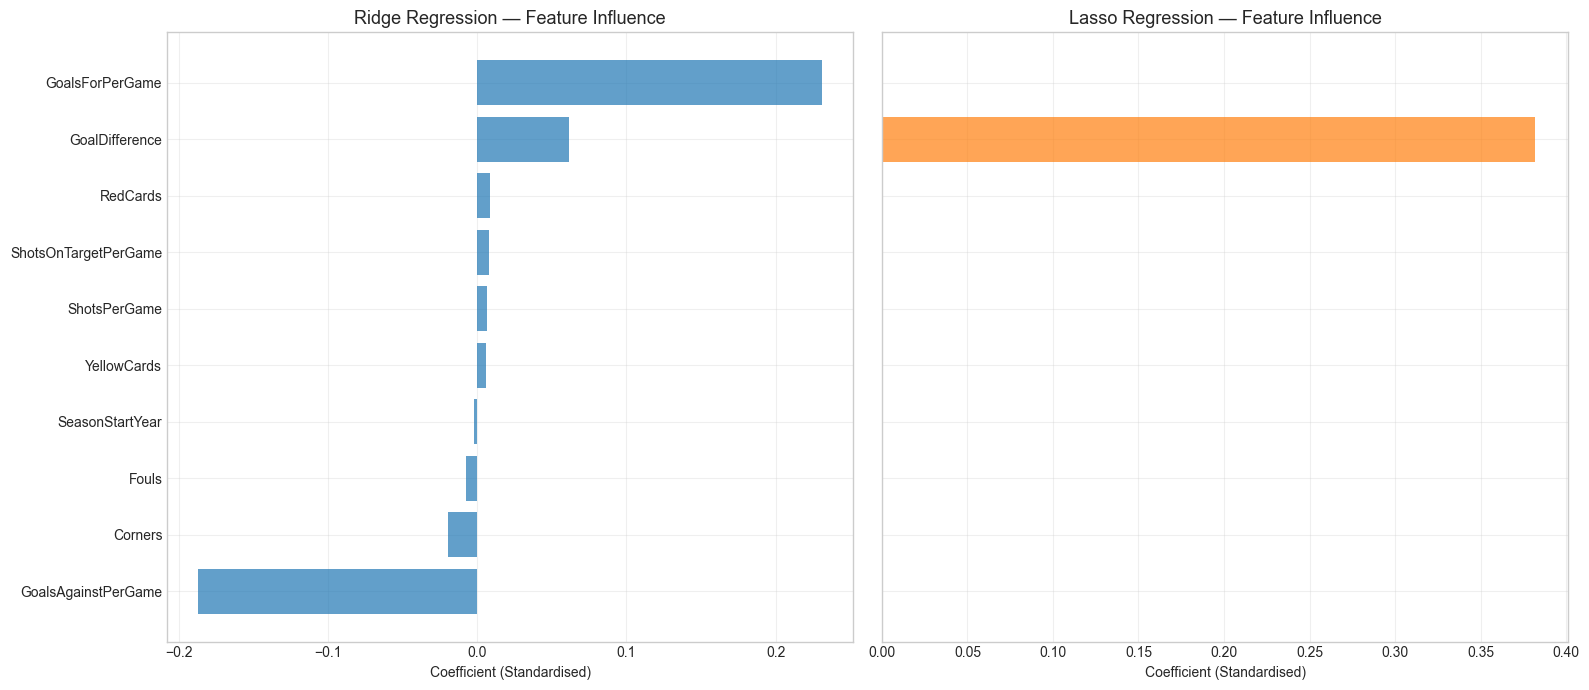

In [56]:
# FEATURE COEFFICIENTS BAR PLOTS
ridge_coef = ridge.coef_
lasso_coef = lasso.coef_

coef_eplData = pd.DataFrame({
    "Feature": feature_cols,
    "Ridge": ridge_coef,
    "Lasso": lasso_coef
})

# Sort separately for cleaner visuals
coef_eplData_ridge = coef_eplData.sort_values("Ridge")
coef_eplData_lasso = coef_eplData.sort_values("Lasso")

# Side-by-side plot
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

# ----- Ridge -----
axes[0].barh(coef_eplData_ridge["Feature"], coef_eplData_ridge["Ridge"], color="#1f77b4", alpha=0.7)
axes[0].set_title("Ridge Regression — Feature Influence", fontsize=13)
axes[0].set_xlabel("Coefficient (Standardised)")
axes[0].grid(alpha=0.3)

# ----- Lasso -----
axes[1].barh(coef_eplData_lasso["Feature"], coef_eplData_lasso["Lasso"], color="#ff7f0e", alpha=0.7)
axes[1].set_title("Lasso Regression — Feature Influence", fontsize=13)
axes[1].set_xlabel("Coefficient (Standardised)")
axes[1].grid(alpha=0.3)

# Layout
plt.tight_layout()
plt.show()